In [1]:
import argparse
import json
import tensorboard
import tensorboardX
import os
import re
import random
import math
import argparse
import json
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim 
import nni
from nni.nas.nn.pytorch import (
    ModelSpace, LayerChoice, MutableConv2d, MutableBatchNorm2d,
    MutableReLU, MutableLinear, MutableMultiheadAttention,
)
from nni.nas.experiment.config import NasExperimentConfig
from pytorch_lightning import Trainer
from nni.nas.evaluator.pytorch import Lightning, ClassificationModule, Trainer
from nni.nas.experiment import NasExperiment
from nni.nas.space import model_context
from nni.nas.hub.pytorch import DARTS
from nni.nas.strategy import DARTS as DartsStrategy
from pytorch_lightning.loggers import TensorBoardLogger
from torch.utils.data import DataLoader
from torch.utils.data.sampler import SubsetRandomSampler
from torchvision import transforms
from torchvision.datasets import CIFAR10
from nni.nas.experiment import NasExperiment
from nni.nas.evaluator import FunctionalEvaluator
import nni.nas.strategy as strategy
from torchvision import transforms
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
from nni.experiment.config import utils, ExperimentConfig
from pytorch_lightning.callbacks import ModelCheckpoint
torch.set_float32_matmul_precision('medium')
from tqdm import tqdm
from nni.nas.nn.pytorch import LayerChoice, ModelSpace, ValueChoice
from torch.utils.data import DataLoader, Dataset, SubsetRandomSampler
from pytorch_lightning import LightningModule, Trainer
from torchvision import datasets, transforms
from nni.nas.evaluator.pytorch import Classification

# Import the quantized CustomDARTSSpace
import sys
import importlib
import os
from pathlib import Path

USER = Path.home().name


root = Path.home() / "TESI_FILIPPO_LUCCHESI"
os.chdir(root)
print(f'Current working directory: {Path.cwd()}')

module_dir = root / "code"
if not (module_dir / "DoReFaLayersV2.py").is_file():
    raise FileNotFoundError(f"DoReFaLayersV2.py not found in {module_dir}")

if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))

import DoReFaLayersV2
from DoReFaLayersV2 import (
    MutableDoReFaConv2d, MutableDoReFaLinear, dorefa_activation,
    dorefa_signed_activation, dorefa_weight,
)
importlib.reload(DoReFaLayersV2)
from DoReFaLayersV2 import (
    MutableDoReFaConv2d, MutableDoReFaLinear, dorefa_activation,
    dorefa_signed_activation, dorefa_weight,
)
from nni.nas.oneshot.pytorch.supermodule.operation import (
    MixedConv2d, MixedLinear, MixedMultiHeadAttention,
)

# Reproducibility settings
SEED = 42
os.environ.setdefault('PYTHONHASHSEED', str(SEED))
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
# torch.use_deterministic_algorithms(True)
# torch.backends.cudnn.benchmark = False
# torch.backends.cudnn.deterministic = True
# if hasattr(torch.backends, 'cuda') and hasattr(torch.backends.cuda, 'matmul'):
#     torch.backends.cuda.matmul.allow_tf32 = False
# if hasattr(torch.backends, 'cudnn'):
#     torch.backends.cudnn.allow_tf32 = False
print(f'Using global seed: {SEED}')


# Define a Conv2d mixed-operation that applies DoReFa weight quantization when used.

class QuantMixedConv2d(MixedConv2d):
    """NNI mixed convolution that preserves DoReFa weight quantization."""

    def forward_with_args(
        self, in_channels, out_channels, kernel_size, stride, padding,
        dilation, groups, inputs,
    ):
        if isinstance(stride, dict) or isinstance(dilation, dict):
            raise ValueError("Mutable stride/dilation is not supported in differentiable mode.")
        params = self._freeze_weight_impl(in_channels, out_channels, kernel_size, groups)
        weight = params.get("weight")
        bias = params.get("bias")
        in_channels_per_group = params.get("in_channels_per_group")
        bits = getattr(self, "num_bits", None)
        if bits is not None:
            weight = dorefa_weight(weight, int(bits))

        if isinstance(groups, dict):
            if not isinstance(in_channels_per_group, (int, float)):
                raise ValueError(
                    f"Input channels per group is not numeric: {in_channels_per_group}"
                )
            if inputs.size(1) % int(in_channels_per_group) != 0:
                raise RuntimeError(
                    "Input channels must be divisible by in_channels_per_group; "
                    f"got {inputs.size(1)} and {in_channels_per_group}."
                )
            groups = inputs.size(1) // int(in_channels_per_group)

        if isinstance(kernel_size, dict):
            if isinstance(self.padding, str):
                raise ValueError(f"Padding mode {self.padding!r} is not supported here.")
            padding = self.padding
        stride = self._to_tuple(stride)
        dilation = self._to_tuple(dilation)
        if self.padding_mode != "zeros":
            return F.conv2d(
                F.pad(inputs, self._reversed_padding_repeated_twice, mode=self.padding_mode),
                weight, bias, stride, (0, 0), dilation, groups,
            )
        return F.conv2d(inputs, weight, bias, stride, padding, dilation, groups)

    @classmethod
    def mutate(cls, module, name, memo, kwargs):
        mixed_op = super().mutate(module, name, memo, kwargs)
        if mixed_op is not None:
            mixed_op.num_bits = getattr(module, "num_bits", None)
            mixed_op.max_epochs = getattr(module, "max_epochs", None)
            mixed_op.epoch = getattr(module, "epoch", None)
        return mixed_op

    def freeze(self, sample):
        arguments = {**self.init_arguments}
        for name, mutable in self.mutable_arguments.items():
            arguments[name] = mutable.freeze(sample)
        operation = self.bound_type(**arguments)
        if hasattr(operation, "num_bits") and getattr(self, "num_bits", None) is not None:
            operation.num_bits = int(self.num_bits)
        operation.load_state_dict(self.freeze_weight(**arguments), strict=False)
        return operation

class SafeMixedLinear(MixedLinear):
    """NNI mixed linear layer that preserves DoReFa weight quantization."""

    def forward_with_args(self, in_features, out_features, inputs):
        params = self.freeze_weight(in_features, out_features)
        weight, bias = params.get("weight"), params.get("bias")
        bits = getattr(self, "num_bits", None)
        if bits is not None:
            weight = dorefa_weight(weight, int(bits))
        return F.linear(inputs, weight, bias)

    @classmethod
    def mutate(cls, module, name, memo, kwargs):
        mixed_op = super().mutate(module, name, memo, kwargs)
        if mixed_op is not None:
            mixed_op.num_bits = getattr(module, "num_bits", None)
            mixed_op.max_epochs = getattr(module, "max_epochs", None)
            mixed_op.epoch = getattr(module, "epoch", None)
        return mixed_op

    def freeze(self, sample):
        arguments = {**self.init_arguments}
        for name, mutable in self.mutable_arguments.items():
            arguments[name] = mutable.freeze(sample)
        operation = self.bound_type(**arguments)
        if hasattr(operation, "num_bits") and getattr(self, "num_bits", None) is not None:
            operation.num_bits = int(self.num_bits)
        operation.load_state_dict(self.freeze_weight(**arguments), strict=False)
        return operation

class QuantMixedSelfAttention(MixedMultiHeadAttention):
    """
    Quantized specialization of NNI's MixedMultiHeadAttention.

    This implementation supports standard Q/K/V attention, but is primarily
    intended for self-attention where query, key, and value have the same
    embedding dimension.
    """



    @classmethod
    @classmethod
    def mutate(cls, module, name, memo, mutate_kwargs):
        mixed_op = super().mutate(module, name, memo, mutate_kwargs)
        if mixed_op is None:
            return None
        mixed_op.num_bits = getattr(module, "num_bits", None)
        mixed_op.act_bits = getattr(module, "act_bits", mixed_op.num_bits)
        if mixed_op.act_bits is not None:
            bits = int(mixed_op.act_bits)
            mixed_op.act_quants = nn.ModuleDict({
                "query": SignedActQuant(k=bits),
                "key": SignedActQuant(k=bits),
                "value": SignedActQuant(k=bits),
                "q_projected": SignedActQuant(k=bits),
                "k_projected": SignedActQuant(k=bits),
                "v_projected": SignedActQuant(k=bits),
                "scores": SignedActQuant(k=bits),
                "probabilities": ActQuant(k=bits),
                "context": SignedActQuant(k=bits),
                "output": SignedActQuant(k=bits),
            })
        return mixed_op

    def _quantize_weight(self, name, weight):
        if weight is None or self.num_bits is None:
            return weight
        return dorefa_weight(weight, int(self.num_bits))

    def _quantize_activation(self, name, value):
        if self.act_bits is None:
            return value
        return self.act_quants[name](value)

    @staticmethod
    def _apply_attention_mask(scores, attn_mask):
        if attn_mask is None:
            return scores
        if attn_mask.dtype == torch.bool:
            return scores.masked_fill(
                attn_mask,
                torch.finfo(scores.dtype).min,
            )
        return scores + attn_mask

    @staticmethod
    def _apply_key_padding_mask(scores, key_padding_mask):
        if key_padding_mask is None:
            return scores
        # [B, source_length] -> [B, 1, 1, source_length]
        mask = key_padding_mask[:, None, None, :]
        if mask.dtype == torch.bool:
            return scores.masked_fill(
                mask,
                torch.finfo(scores.dtype).min,
            )
        return scores + mask

    def forward_with_args(
        self,
        # These five arguments must match argument_list from
        # MixedMultiHeadAttention.
        embed_dim,
        num_heads,
        kdim,
        vdim,
        dropout,
        # Runtime forward arguments.
        query,
        key,
        value,
        key_padding_mask=None,
        need_weights=True,
        attn_mask=None,
        average_attn_weights=True,
        is_causal=False,
    ):
        # DARTS does not support differentiable mixtures of num_heads or
        # dropout in NNI's built-in implementation.
        if isinstance(num_heads, dict):
            raise ValueError(
                "Mutable num_heads is not supported by DARTS. "
                "Use a LayerChoice of complete attention candidates."
            )
        if isinstance(dropout, dict):
            raise ValueError(
                "Mutable dropout is not supported by DARTS."
            )
        if is_causal and attn_mask is None:
            target_length = query.size(1 if self.batch_first else 0)
            source_length = key.size(1 if self.batch_first else 0)
            attn_mask = torch.ones(
                target_length,
                source_length,
                device=query.device,
                dtype=torch.bool,
            ).triu(diagonal=1)
        if self.batch_first:
            # Internal representation: [sequence, batch, channels].
            query = query.transpose(0, 1)
            key = key.transpose(0, 1)
            value = value.transpose(0, 1)
        # For a differentiable weighted embed_dim choice, NNI keeps the
        # maximum-sized representation and mixes sliced parameters.
        used_embed_dim = (
            self.embed_dim
            if isinstance(embed_dim, dict)
            else embed_dim
        )
        if used_embed_dim % num_heads != 0:
            raise ValueError(
                f"embed_dim={used_embed_dim} must be divisible by "
                f"num_heads={num_heads}"
            )
        head_dim = used_embed_dim // num_heads
        # Reuse NNI's tested logic for slicing/mixing the supernet weights.
        params = self._freeze_weight_impl(
            embed_dim,
            kdim,
            vdim,
        )
        in_proj_weight = params["in_proj_weight"]
        in_proj_bias = params["in_proj_bias"]

        q_proj_weight = params["q_proj_weight"]
        k_proj_weight = params["k_proj_weight"]
        v_proj_weight = params["v_proj_weight"]

        out_proj_weight = params["out_proj.weight"]
        out_proj_bias = params["out_proj.bias"]

        qkv_same_embed_dim = params["qkv_same_embed_dim"]

        query = self._quantize_activation("query", query)
        key = self._quantize_activation("key", key)
        value = self._quantize_activation("value", value)

        if qkv_same_embed_dim:
            in_proj_weight = self._quantize_weight(
                "in_proj",
                in_proj_weight,
            )

            q_weight, k_weight, v_weight = (
                in_proj_weight.chunk(3, dim=0)
            )

            if in_proj_bias is None:
                q_bias = k_bias = v_bias = None
            else:
                q_bias, k_bias, v_bias = (
                    in_proj_bias.chunk(3, dim=0)
                )

        else:
            q_weight = self._quantize_weight(
                "q_proj_weight",
                q_proj_weight,
            )
            k_weight = self._quantize_weight(
                "k_proj_weight",
                k_proj_weight,
            )
            v_weight = self._quantize_weight(
                "v_proj_weight",
                v_proj_weight,
            )

            if in_proj_bias is None:
                q_bias = k_bias = v_bias = None
            else:
                q_bias, k_bias, v_bias = (
                    in_proj_bias.chunk(3, dim=0)
                )

        q = F.linear(query, q_weight, q_bias)
        k = F.linear(key, k_weight, k_bias)
        v = F.linear(value, v_weight, v_bias)

        q = self._quantize_activation("q_projected", q)
        k = self._quantize_activation("k_projected", k)
        v = self._quantize_activation("v_projected", v)

        target_length, batch_size, _ = q.shape
        source_length = k.size(0)

        # [L, B, C] -> [B, heads, L, head_dim]
        q = (
            q.reshape(
                target_length,
                batch_size,
                num_heads,
                head_dim,
            )
            .permute(1, 2, 0, 3)
        )

        k = (
            k.reshape(
                source_length,
                batch_size,
                num_heads,
                head_dim,
            )
            .permute(1, 2, 0, 3)
        )

        v = (
            v.reshape(
                source_length,
                batch_size,
                num_heads,
                head_dim,
            )
            .permute(1, 2, 0, 3)
        )

        scores = torch.matmul(
            q,
            k.transpose(-2, -1),
        )
        scores = scores / math.sqrt(head_dim)

        # Quantize before applying masks. Quantizing a masked -inf value
        # would turn it into a finite value and break masking.
        scores = self._quantize_activation("scores", scores)

        scores = self._apply_attention_mask(
            scores,
            attn_mask,
        )
        scores = self._apply_key_padding_mask(
            scores,
            key_padding_mask,
        )

        probabilities = torch.softmax(scores, dim=-1)
        probabilities = F.dropout(
            probabilities,
            p=dropout,
            training=self.training,
        )

        probabilities = self._quantize_activation(
            "probabilities",
            probabilities,
        )

        context = torch.matmul(probabilities, v)
        context = self._quantize_activation(
            "context",
            context,
        )

        # [B, heads, L, head_dim] -> [L, B, C]
        context = (
            context.permute(2, 0, 1, 3)
            .contiguous()
            .reshape(
                target_length,
                batch_size,
                used_embed_dim,
            )
        )

        out_proj_weight = self._quantize_weight(
            "out_proj",
            out_proj_weight,
        )

        output = F.linear(
            context,
            out_proj_weight,
            out_proj_bias,
        )

        output = self._quantize_activation(
            "output",
            output,
        )

        if self.batch_first:
            output = output.transpose(0, 1)

        if not need_weights:
            return output, None

        if average_attn_weights:
            returned_weights = probabilities.mean(dim=1)
        else:
            returned_weights = probabilities

        return output, returned_weights

    def freeze(self, sample):
        # Match QuantMixedConv2d/SafeMixedLinear: freeze the sampled NNI
        # constructor arguments and copy the sliced supernet weights.
        arguments = {**self.init_arguments}
        for name, mutable in self.mutable_arguments.items():
            arguments[name] = mutable.freeze(sample)
        operation = self.bound_type(**arguments)
        state_dict = self.freeze_weight(**arguments)
        operation.load_state_dict(state_dict, strict=False)
        return operation

def safe_mutable_conv_hook(module, name, memo, kwargs):
    if isinstance(module, MutableDoReFaConv2d):
        return QuantMixedConv2d.mutate(module, name, memo, kwargs)
    return False


def safe_mutable_linear_hook(module, name, memo, kwargs):
    if isinstance(module, MutableDoReFaLinear):
        return SafeMixedLinear.mutate(module, name, memo, kwargs)
    return False


def safe_mutable_attention_hook(module, name, memo, kwargs):
    if isinstance(module, MutableDoReFaSelfAttention):
        return QuantMixedSelfAttention.mutate(module, name, memo, kwargs)
    return False


Current working directory: /home/cc/TESI_FILIPPO_LUCCHESI
Using global seed: 42


/home/cc/miniconda3/envs/pytorch-env/lib/python3.11/site-packages/nni/nas/nn/pytorch/layers.py:94: RuntimeWarning: <class 'torch.nn.parameter.Buffer'> is found to be not a nn.Module, which is unexpected. It means your PyTorch version might not be supported.
  warnings.warn(f'{obj} is found to be not a nn.Module, which is unexpected. '
/home/cc/miniconda3/envs/pytorch-env/lib/python3.11/site-packages/nni/nas/nn/pytorch/layers.py:94: RuntimeWarning: <class 'torch.nn.modules.linear_cross_entropy_options.LinearCrossEntropyOptions'> is found to be not a nn.Module, which is unexpected. It means your PyTorch version might not be supported.
  warnings.warn(f'{obj} is found to be not a nn.Module, which is unexpected. '


In [2]:
import psutil
import os

p = psutil.Process(os.getpid())

p.nice(19)

# Quantized DARTS Architecture Search

This notebook performs NAS using the quantized CustomDARTSSpace with DoReFa quantization-aware training.

# Data Loading and Augmentation

In [3]:
def cutout_transform(img, length: int = 16):
    h, w = img.size(1), img.size(2)
    mask = np.ones((h, w), np.float32)
    y = np.random.randint(h)
    x = np.random.randint(w)

    y1 = np.clip(y - length // 2, 0, h)
    y2 = np.clip(y + length // 2, 0, h)
    x1 = np.clip(x - length // 2, 0, w)
    x2 = np.clip(x + length // 2, 0, w)

    mask[y1: y2, x1: x2] = 0.
    mask = torch.from_numpy(mask)
    mask = mask.expand_as(img)
    img *= mask
    return img

In [4]:
normalize = transforms.Normalize(
                (0.4914, 0.4822, 0.4465),
                (0.2470, 0.2435, 0.2616)
            ) 

def get_cifar10_dataset(valid: bool = False, train: bool = True, cutout: bool = False):
    if train and not valid:
        transform_list = [
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ToTensor(),
        ]
        if cutout:
            transform_list.append(cutout_transform)
        transform = transforms.Compose(transform_list)
    else:
        transform = transforms.Compose([
            transforms.ToTensor(), 
        ])

    dataset = nni.trace(CIFAR10)(root='./data', train=train, download=True, transform=transform)
    
    return dataset

def stratified_split_indices(dataset, val_fraction=0.2, seed=42):
    rng = np.random.default_rng(seed)
    labels = np.array(dataset.targets, dtype=int)
    train_indices = []
    val_indices = []
    for label in np.unique(labels):
        label_indices = np.where(labels == label)[0]
        rng.shuffle(label_indices)
        if len(label_indices) <= 1:
            train_indices.extend(label_indices.tolist())
            continue
        val_count = max(1, int(round(len(label_indices) * val_fraction)))
        val_count = min(val_count, len(label_indices) - 1)
        val_indices.extend(label_indices[:val_count].tolist())
        train_indices.extend(label_indices[val_count:].tolist())
    rng.shuffle(train_indices)
    rng.shuffle(val_indices)
    return train_indices, val_indices

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    random.seed(worker_seed)
    np.random.seed(worker_seed)
    torch.manual_seed(worker_seed)

from torch.utils.data import Subset

batch_size = 128
full_train_data = get_cifar10_dataset(train=True, cutout=True)
test_data = get_cifar10_dataset(train=False)
clean_train_data = get_cifar10_dataset(train=True, cutout=False, valid=True)

train_indices, valid_indices = stratified_split_indices(full_train_data, val_fraction=0.2, seed=SEED)
train_data = Subset(full_train_data, train_indices)
valid_data = Subset(clean_train_data, valid_indices)

print(f"Full training samples: {len(full_train_data)}")
print(f"Training split samples: {len(train_data)}")
print(f"Validation split samples: {len(valid_data)}")
print(f"Test samples: {len(test_data)}")

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    pin_memory=True,
    num_workers=6,
    persistent_workers=True,
    shuffle=True,
    worker_init_fn=seed_worker,
    generator=train_generator,
 )

valid_loader = DataLoader(
    valid_data,
    batch_size=batch_size,
    pin_memory=True,
    num_workers=6,
    persistent_workers=True,
    shuffle=False,
    worker_init_fn=seed_worker,
 )

Full training samples: 50000
Training split samples: 40000
Validation split samples: 10000
Test samples: 10000


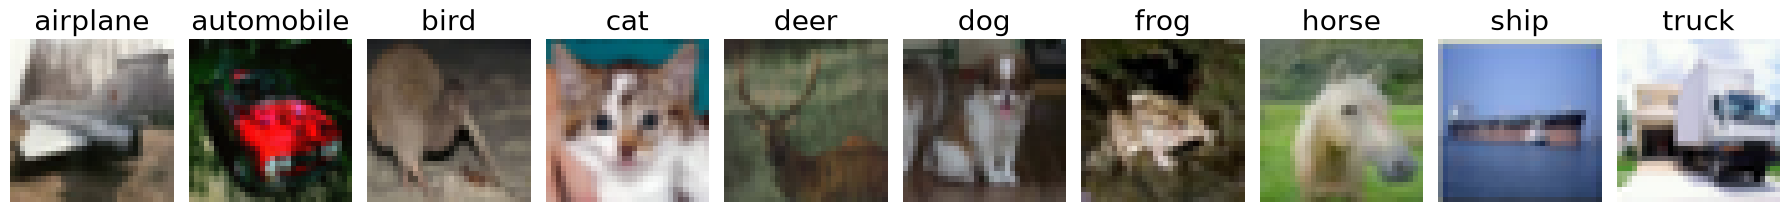

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Use the raw CIFAR-10 training data so the images are unaugmented.
dataset = globals().get("clean_train_data", None)
if dataset is None:
    dataset = globals().get("full_train_data", None)
if dataset is None:
    from torchvision import datasets
    dataset = datasets.CIFAR10(root="./data", train=True, download=True)

if hasattr(dataset, "dataset"):
    raw_data = dataset.dataset.data
    raw_targets = dataset.dataset.targets
else:
    raw_data = dataset.data
    raw_targets = dataset.targets

classes = list(dataset.classes)
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, len(classes), figsize=(18, 2.4))

for ax, cls in zip(axes, classes):
    class_idx = dataset.class_to_idx[cls]
    targets = np.array(raw_targets)
    class_indices = np.where(targets == class_idx)[0]
    sample_idx = int(class_indices[rng.integers(0, len(class_indices))])
    img_np = raw_data[sample_idx]

    ax.imshow(img_np)
    ax.set_title(cls, fontsize=20)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Classification Module

In [6]:
from nni.nas.oneshot.pytorch.supermodule.operation import (
    MixedConv2d,
    MixedLinear,
 )


@nni.trace
class DartsClassificationModule(ClassificationModule):
    def __init__(self, learning_rate: float = 0.001, 
                 weight_decay: float = 0., 
                 auxiliary_loss_weight=None, 
                 max_epochs: int = 600,
                 alpha_tracker=None,
                 auxiliary_exit_weights=None):
        super().__init__(learning_rate=learning_rate, 
                        weight_decay=weight_decay, 
                        export_onnx=False, 
                        num_classes=10)
        self.auxiliary_loss_weight = auxiliary_loss_weight
        self.auxiliary_exit_weights = auxiliary_exit_weights
        self.max_epochs = max_epochs
        self.alpha_tracker = alpha_tracker
        self._last_alpha_capture_epoch = None
        self.alpha_grads = {}
        self.learning_rate = learning_rate
        self._use_aux_exits = (auxiliary_loss_weight is not None) or (auxiliary_exit_weights is not None)
        self._logged_aux_mode = False
    
    def configure_optimizers(self):
        weight_params = []
        arch_params = []

        for name, p in self.named_parameters():
            if not p.requires_grad:
                continue

            if '_arch_alpha' in name:
                arch_params.append(p)
            else:
                weight_params.append(p)

        print(f"Weight params: {len(weight_params)}")
        print(f"Arch params (excluded): {len(arch_params)}")

        optimizer = torch.optim.SGD(
            weight_params,  # ✅ ONLY weights
            lr=self.learning_rate,
            momentum=0.9,
            weight_decay=0.
        )

        return {
            'optimizer': optimizer,
            'lr_scheduler': torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=self.max_epochs, eta_min=0.001
            )
        }   

    def _sync_epoch_to_quant_modules(self, epoch: int) -> None:
        model = getattr(self, '_model', getattr(self, 'model', None))
        if model is None:
            return
        for module in model.modules():
            if hasattr(module, 'num_bits'):
                module.epoch = epoch
                module.max_epochs = self.max_epochs

    def _resolve_outputs(self, outputs):
        if isinstance(outputs, tuple) and len(outputs) == 2:
            y_hat, aux = outputs
            if isinstance(aux, list):
                return y_hat, aux
            return y_hat, [(-1, aux)]
        return outputs, []

    def _compute_aux_exit_loss(self, exit_logits, y):
        if not exit_logits or not self.auxiliary_loss_weight:
            return None
        weights = self.auxiliary_exit_weights
        if weights is None:
            weights = [self.auxiliary_loss_weight] * len(exit_logits)
        total = 0.0
        used = 0
        final_layer_index = None
        model = getattr(self, '_model', getattr(self, 'model', None))
        if model is not None and hasattr(model, 'layers'):
            final_layer_index = len(model.layers)
        for (layer_idx, logits), weight in zip(exit_logits, weights):
            if final_layer_index is not None and layer_idx == final_layer_index:
                continue
            total = total + float(weight) * self.criterion(logits, y)
            used += 1
        if used == 0:
            return None
        return total

    def training_step(self, batch, batch_idx):
        """Training step, customized with auxiliary loss."""
        x, y = batch
        epoch = self.trainer.current_epoch if self.trainer else 0
        self._sync_epoch_to_quant_modules(epoch)
        model = getattr(self, '_model', getattr(self, 'model', None))
        if model is None:
            raise RuntimeError('DartsClassificationModule has no attached model.')
        if self._use_aux_exits:
            outputs = model(x, epoch=epoch, return_all_exits=True)
            y_hat, exit_logits = self._resolve_outputs(outputs)
        else:
            if not self._logged_aux_mode:
                print("Aux exits disabled: running standard forward without exit logits.")
                self._logged_aux_mode = True
            y_hat = model(x, epoch=epoch)
            exit_logits = []
        loss_main = self.criterion(y_hat, y)
        loss = loss_main
        aux_loss = self._compute_aux_exit_loss(exit_logits, y)
        if aux_loss is not None:
            loss = loss + aux_loss
            self.log('train_loss_aux', aux_loss)
        self.log('train_loss_main', loss_main)
        self.log('train_loss', loss, prog_bar=True)
        for name, metric in self.metrics.items():
            self.log('train_' + name, metric(y_hat, y), prog_bar=True)
        #if batch_idx % 100 == 0:  # Log alpha stats every 5 epochs to reduce overhead
            #self.log_alpha_grads()
            #self.log_alphas()
        return loss
    
    def validation_step(self, batch, batch_idx):
        """Validate the final target-bit inference path, independent of warm-up."""
        x, y = batch
        epoch = self.trainer.current_epoch if self.trainer else 0
        self._sync_epoch_to_quant_modules(epoch)
        model = getattr(self, '_model', getattr(self, 'model', None))
        if model is None:
            raise RuntimeError('DartsClassificationModule has no attached model.')

        # NAS warm-up toggles use_fp on mixed operations. Restore those flags
        # after validation so the following training batch resumes its phase.
        fp_state = [
            (module, bool(module.use_fp))
            for module in model.modules()
            if hasattr(module, 'use_fp')
        ]
        try:
            if hasattr(model, 'forward_validation'):
                outputs = model.forward_validation(x)
            else:
                outputs = model(x, epoch=epoch, inference=True)
        finally:
            for module, previous_use_fp in fp_state:
                module.use_fp = previous_use_fp

        y_hat, _ = self._resolve_outputs(outputs)
        loss = self.criterion(y_hat, y)
        self.log(
            'val_loss',
            loss,
            prog_bar=True,
            on_step=False,
            on_epoch=True,
            batch_size=y.size(0),
        )
        for name, metric in self.metrics.items():
            self.log(
                'val_' + name,
                metric(y_hat, y),
                prog_bar=True,
                on_step=False,
                on_epoch=True,
                batch_size=y.size(0),
            )
        return loss

    def log_alpha_grads(self):
        if not self.alpha_grads:
            print("No alpha gradients recorded yet.")
            return

        print("\n=== Alpha Gradient Stats ===")
        for name, g in self.alpha_grads.items():
            mean = g.mean().item()
            std = g.std().item()
            print(f"{name}: mean={mean:.6e}, std={std:.6e}")
    
    def log_alphas(self):
        print("\n=== Alpha Values ===")
        for name, p in self.named_parameters():
            if 'alpha' in name.lower():
                probs = torch.softmax(p, dim=-1)
                print(f"{name}: {probs.detach().cpu().numpy()}")

    def get_temperature(self, epoch, max_epochs):
        # cosine decay from 5 → 0.1
        import math
        T_max = 5.0
        T_min = 0.1
        return T_min + 0.5 * (T_max - T_min) * (1 + math.cos(math.pi * epoch / max_epochs))

    def apply_alpha_temperature(self, T):
        for name, p in self.named_parameters():
            if 'alpha' in name.lower():
                p.data = p.data / T

    def on_train_epoch_start(self):
        # Logging learning rate at the beginning of every epoch
        self.log('lr', self.trainer.optimizers[0].param_groups[0]['lr'])
        #self.ema = EMA(self.model, decay=0.999)
        #epoch = self.trainer.current_epoch
        #T = self.get_temperature(epoch, self.max_epochs)

        #self.apply_alpha_temperature(T)

        #self.log('temperature', T)
    
    def on_after_backward(self):
        #self.ema.update(self.model)
        return

    def attach_alpha_hooks(self):
        """Register backward hooks to capture gradients of architecture parameters."""
        for name, p in self.named_parameters():
            if p.requires_grad and 'alpha' in name.lower():

                def make_hook(name):
                    def hook(grad):
                        self.alpha_grads[name] = grad.detach().clone()
                    return hook

                p.register_hook(make_hook(name))
                
    def _verify_custom_quant_runtime(self):
        model = getattr(self, '_model', getattr(self, 'model', None))
        if model is None:
            raise RuntimeError('Cannot verify quantized runtime without an attached model.')

        modules = list(model.modules())
        quant_convs = sum(isinstance(m, QuantMixedConv2d) for m in modules)
        quant_linears = sum(isinstance(m, SafeMixedLinear) for m in modules)
        quant_attentions = sum(
            isinstance(m, QuantMixedSelfAttention) for m in modules
        )

        leftovers = [
            type(m).__name__
            for m in modules
            if isinstance(
                m,
                (
                    MutableDoReFaConv2d,
                    MutableDoReFaLinear,
                    MutableDoReFaSelfAttention,
                ),
            )
        ]

        if leftovers:
            raise RuntimeError(
                'Custom mutable modules survived NNI mutation: '
                + ', '.join(sorted(set(leftovers)))
            )
        if quant_convs == 0 or quant_linears == 0:
            raise RuntimeError(
                'Quantized convolution/linear hooks were not applied.'
            )
        if quant_attentions == 0:
            raise RuntimeError(
                'Attention candidates exist, but QuantMixedSelfAttention '
                'was not installed by the mutation hook.'
            )

        print(
            'Verified custom NNI runtime modules: '
            f'{quant_convs} QuantMixedConv2d, '
            f'{quant_linears} SafeMixedLinear, '
            f'{quant_attentions} QuantMixedSelfAttention.'
        )

    def on_train_start(self):
        self._verify_custom_quant_runtime()
        self.attach_alpha_hooks()
        print("\n=== Attached alpha gradient hooks ===\n")

    def _capture_alphas_once_per_epoch(self, hook_name: str):
        if self.alpha_tracker is None:
            return

        epoch = int(self.trainer.current_epoch)
        if self._last_alpha_capture_epoch == epoch:
            return

        try:
            self.alpha_tracker.capture_alphas(self, epoch)
            self._last_alpha_capture_epoch = epoch
            # print(f"AlphaTracker: captured at epoch {epoch} from {hook_name}")
        except Exception as e:
            print(f"Alpha capture failed at epoch {epoch} during {hook_name}: {e}")

    def on_train_epoch_end(self):
        self._capture_alphas_once_per_epoch("epoch_end")

    def on_validation_epoch_end(self):
        self._capture_alphas_once_per_epoch("on_validation_epoch_end")



    

In [7]:
class DepthwiseSeparableBlock(nn.Module):
    """
    MobileNet-style depthwise separable block.
    """

    def __init__(self, in_channels, out_channels, stride, num_bits):
        super().__init__()

        self.block = nn.Sequential(
            MutableDoReFaConv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                padding=1,
                stride = stride,
                groups=in_channels,
                bias=False,
                num_bits=num_bits,
            ),

            MutableBatchNorm2d(in_channels),
            nn.ReLU6(inplace=False),
            # Quantize the depthwise activation before pointwise convolution.
            ActQuant(k=num_bits),

            # pointwise
            MutableDoReFaConv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False,
                num_bits=num_bits,
            ),

            MutableBatchNorm2d(out_channels),
            nn.ReLU6(inplace=False),
        )

    def forward(self, x):
        return self.block(x)


class DilatedDepthwiseSeparableBlock(nn.Module):
    """Depthwise-separable 3x3 convolution with a 5x5 effective field."""

    def __init__(self, in_channels, out_channels, stride, num_bits, dilation=2):
        super().__init__()
        self.block = nn.Sequential(
            MutableDoReFaConv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation,
                stride=stride,
                groups=in_channels,
                bias=False,
                num_bits=num_bits,
            ),
            MutableBatchNorm2d(in_channels),
            nn.ReLU6(inplace=False),
            # Match the ordinary depthwise-separable quantization boundary.
            ActQuant(k=num_bits),
            MutableDoReFaConv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False,
                num_bits=num_bits,
            ),
            MutableBatchNorm2d(out_channels),
            nn.ReLU6(inplace=False),
        )

    def forward(self, x):
        return self.block(x)


class ZeroOp(nn.Module):
    """Zero main branch; the outer ResidualBlock supplies the true skip."""

    def __init__(self, out_channels):
        super().__init__()
        self.out_channels = int(out_channels)

    def forward(self, x):
        return x.new_zeros(
            x.size(0), self.out_channels, x.size(2), x.size(3)
        )


In [8]:
class ActQuant(nn.Module):
    """Unsigned 4-bit DoReFa activation quantizer for non-negative CNN tensors."""

    def __init__(self, k=6, **_ignored):
        super().__init__()
        self.k = int(k)

    def forward(self, x):
        return dorefa_activation(x, self.k)


class SignedActQuant(nn.Module):
    """Signed DoReFa quantizer for BatchNorm, LayerNorm and attention tensors."""

    def __init__(self, k=6, **_ignored):
        super().__init__()
        self.k = int(k)

    def forward(self, x):
        return dorefa_signed_activation(x, self.k)

class MutableDoReFaSelfAttention(MutableMultiheadAttention):
    """NNI mutable MHA carrying fixed quantization metadata.

    num_bits and act_bits are deliberately removed from trace_kwargs:
    they are not architecture choices.  The attention mutation hook copies
    them to QuantMixedSelfAttention, just like the convolution/linear hooks.
    """

    def __init__(
        self,
        embed_dim,
        num_heads,
        dropout=0.0,
        bias=True,
        add_bias_kv=False,
        add_zero_attn=False,
        kdim=None,
        vdim=None,
        batch_first=False,
        device=None,
        dtype=None,
        num_bits=4,
        act_bits=None,
    ):
        super().__init__(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            bias=bias,
            add_bias_kv=add_bias_kv,
            add_zero_attn=add_zero_attn,
            kdim=kdim,
            vdim=vdim,
            batch_first=batch_first,
            device=device,
            dtype=dtype,
        )
        self.num_bits = int(num_bits)
        self.act_bits = int(num_bits if act_bits is None else act_bits)
        self.trace_kwargs.pop('num_bits', None)
        self.trace_kwargs.pop('act_bits', None)


class SpatialSelfAttentionBlock(nn.Module):
    """Adapt NCHW CNN features to NNI multi-head self-attention."""

    def __init__(self, in_channels, out_channels, num_heads, num_bits):
        super().__init__()
        if out_channels % num_heads != 0:
            raise ValueError(
                f'out_channels={out_channels} must be divisible by '
                f'num_heads={num_heads}'
            )

        if in_channels == out_channels:
            self.input_projection = nn.Identity()
        else:
            self.input_projection = nn.Sequential(
                MutableDoReFaConv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=1,
                    padding=0,
                    bias=False,
                    num_bits=num_bits,
                ),
                MutableBatchNorm2d(out_channels),
                nn.ReLU6(inplace=False),
            )

        # Pre-normalization produces signed values. QuantMixedSelfAttention
        # immediately applies its signed query/key/value quantizers.
        self.pre_norm = nn.LayerNorm(out_channels)
        self.attention = MutableDoReFaSelfAttention(
            embed_dim=out_channels,
            num_heads=num_heads,
            dropout=0.0,
            bias=False,
            batch_first=True,
            num_bits=num_bits,
            act_bits=num_bits,
        )
        self.output_bn = MutableBatchNorm2d(out_channels)
        self.output_relu = nn.ReLU6(inplace=False)

    def forward(self, x):
        x = self.input_projection(x)
        batch, channels, height, width = x.shape
        tokens = x.flatten(2).transpose(1, 2)
        tokens = self.pre_norm(tokens)
        tokens, _ = self.attention(
            tokens,
            tokens,
            tokens,
            need_weights=False,
        )
        x = tokens.transpose(1, 2).reshape(
            batch,
            channels,
            height,
            width,
        )
        x = self.output_bn(x)
        return self.output_relu(x)


class ResidualBlock(nn.Module):
    def __init__(self, op: nn.Module, in_channels: int, out_channels: int, num_bits: int):
        super().__init__()
        self.op = op
        if in_channels != out_channels:
            self.proj = nn.Sequential(
                MutableDoReFaConv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=1,
                    bias=False,
                    num_bits=num_bits,
                ),
                MutableBatchNorm2d(out_channels),
            )
        else:
            self.proj = nn.Identity()

        # Candidate operations end in ReLU, so the main branch is unsigned.
        # A projection residual ends in BatchNorm, so keep it signed.
        self.main_branch_quant = ActQuant(k=num_bits)
        self.residual_branch_quant = SignedActQuant(k=num_bits)
        # c = 2 * sigmoid(logit): c starts at 1 and stays in (0, 2).
        self.residual_scale_logit = nn.Parameter(torch.tensor(0.0))
        self.post_relu = nn.ReLU6(inplace=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.op(x)
        res = self.proj(x)
        residual_scale = 2.0 * torch.sigmoid(self.residual_scale_logit)
        res = residual_scale * res
        out = self.main_branch_quant(out)
        res = self.residual_branch_quant(res)
        #print(f"Residual block: op output shape {out.shape}, residual shape {res.shape}")
        return self.post_relu(out + res)


class SkipConnect(nn.Module):
    def __init__(self, in_channels, out_channels, num_bits):
        super().__init__()
        if in_channels == out_channels:
            self.op = nn.Identity()
        else:
            # Cheap 1x1 projection to match channel dimensions
            self.op = nn.Sequential(
                MutableDoReFaConv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=1,
                    padding=0,
                    bias=False,
                    num_bits=num_bits,
                ),
                MutableBatchNorm2d(out_channels)
            )

    def forward(self, x):
        return self.op(x)

class CustomDARTSSpaceResidual(ModelSpace):
    """CustomDARTSSpace with always-on residuals inside each block."""

    def __init__(
        self,
        input_channels: int = 3,
        channels: int = 64,
        num_classes: int = 10,
        layers: int = 7,
        verbose: int = 0,
        drop_path_prob: float = 0.1,
        num_bits: int = 6,
        max_epochs: int = 200,
    ):
        super().__init__()
        self.layers = nn.ModuleList()
        self.downsamples = nn.ModuleList()
        self.drop_path_prob = drop_path_prob
        self.verbose = verbose
        self.max_epochs = max_epochs
        self.num_bits = num_bits
        self.downsample_indices = {1, 3, 6}

        layer0_out = 32
        layer1_out = 32
        layer2_out = 64
        layer3_out = 64
        layer4_out = 128
        layer5_out = 128
        layer6_out = 256
        layer7_out = 200

        self.preliminary_layer = MutableDoReFaConv2d(
            input_channels,
            layer0_out,
            kernel_size=3,
            padding=1,
            bias=False,
            num_bits=num_bits,
        )
        self.layer0_bn = MutableBatchNorm2d(layer0_out)
        self.layer0_relu = nn.ReLU6(inplace=False)


        def _downsample_choice(channels, label):
            return LayerChoice(
                [
                    nn.AvgPool2d(kernel_size=2, stride=2),
                    nn.Sequential(
                        MutableDoReFaConv2d(
                            channels,
                            channels,
                            kernel_size=1,
                            stride=2,
                            bias=False,
                            num_bits=num_bits,
                        ),
                        MutableBatchNorm2d(channels),
                    ),
                ],
                label=label,
            )

        def _residual_layer(op_choice: nn.Module, in_ch: int, out_ch: int):
            return ResidualBlock(op_choice, in_ch, out_ch, num_bits)

        def _attention_candidate(in_ch: int, out_ch: int):
            # Attention is offered only once features are 8x8. DARTS evaluates
            # every LayerChoice candidate, so using global attention at 32x32
            # or 16x16 would make the score tensor unnecessarily large.
            return SpatialSelfAttentionBlock(
                in_channels=in_ch,
                out_channels=out_ch,
                num_heads=8,
                num_bits=num_bits,
            )

        layer1_op = LayerChoice(
            [

                nn.Sequential(
                    MutableDoReFaConv2d(
                        layer0_out,
                        layer1_out,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    MutableBatchNorm2d(layer1_out),
                    nn.ReLU6(inplace=False),
                ),
                DepthwiseSeparableBlock(
                    layer0_out,
                    layer1_out,
                    stride=1,
                    num_bits=num_bits,
                ),
                #SkipConnect(layer0_out, layer1_out, num_bits),
            ],
            label="layer_1_op",
        )
        self.layers.append(_residual_layer(layer1_op, layer0_out, layer1_out))
        self.downsamples.append(nn.Identity())

        layer2_op = LayerChoice(
            [
                nn.Sequential(
                    MutableDoReFaConv2d(
                        layer1_out,
                        layer2_out,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    MutableBatchNorm2d(layer2_out),
                    nn.ReLU6(inplace=False),
                ),
                DepthwiseSeparableBlock(
                    layer1_out,
                    layer2_out,
                    stride=1,
                    num_bits=num_bits,
                ),
            ],
            label="layer_2_op",
        )
        self.layers.append(_residual_layer(layer2_op, layer1_out, layer2_out))
        self.downsamples.append(_downsample_choice(layer2_out, "layer_2_down"))

        layer3_op = LayerChoice(
            [
                nn.Sequential(
                    MutableDoReFaConv2d(
                        layer2_out,
                        layer3_out,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    MutableBatchNorm2d(layer3_out),
                    nn.ReLU6(inplace=False),
                ),
                DepthwiseSeparableBlock(
                    layer2_out,
                    layer3_out,
                    stride=1,
                    num_bits=num_bits,
                ),
                ZeroOp(layer3_out),
                DilatedDepthwiseSeparableBlock(
                    layer2_out,
                    layer3_out,
                    stride=1,
                    num_bits=num_bits,
                    dilation=2,
                ),
            ],
            label="layer_3_op",
        )
        self.layers.append(_residual_layer(layer3_op, layer2_out, layer3_out))
        self.downsamples.append(nn.Identity())

        layer4_op = LayerChoice(
            [
                nn.Sequential(
                    MutableDoReFaConv2d(
                        layer3_out,
                        layer4_out,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    MutableBatchNorm2d(layer4_out),
                    nn.ReLU6(inplace=False),
                ),
                DepthwiseSeparableBlock(
                    layer3_out,
                    layer4_out,
                    stride=1,
                    num_bits=num_bits,
                ),
                ZeroOp(layer4_out),
                DilatedDepthwiseSeparableBlock(
                    layer3_out,
                    layer4_out,
                    stride=1,
                    num_bits=num_bits,
                    dilation=2,
                ),
            ],
            label="layer_4_op",
        )
        self.layers.append(_residual_layer(layer4_op, layer3_out, layer4_out))
        self.downsamples.append(_downsample_choice(layer4_out, "layer_4_down"))

        layer5_op = LayerChoice(
            [
                nn.Sequential(
                    MutableDoReFaConv2d(
                        layer4_out,
                        layer5_out,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    MutableBatchNorm2d(layer5_out),
                    nn.ReLU6(inplace=False),
                ),
                DepthwiseSeparableBlock(
                    layer4_out,
                    layer5_out,
                    stride=1,
                    num_bits=num_bits,
                ),
                _attention_candidate(layer4_out, layer5_out),
                #SkipConnect(layer4_out, layer5_out, num_bits),
            ],
            label="layer_5_op",
        )
        self.layers.append(_residual_layer(layer5_op, layer4_out, layer5_out))
        self.downsamples.append(nn.Identity())

        layer6_op = LayerChoice(
            [
                nn.Sequential(
                    MutableDoReFaConv2d(
                        layer5_out,
                        layer6_out,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    MutableBatchNorm2d(layer6_out),
                    nn.ReLU6(inplace=False),
                ),
                DepthwiseSeparableBlock(
                    layer5_out,
                    layer6_out,
                    stride=1,
                    num_bits=num_bits,
                ),
                _attention_candidate(layer5_out, layer6_out),
                #SkipConnect(layer5_out, layer6_out, num_bits),
            ],
            label="layer_6_op",
        )
        self.layers.append(_residual_layer(layer6_op, layer5_out, layer6_out))
        self.downsamples.append(nn.Identity())

        layer7_op = LayerChoice(
            [
                nn.Sequential(
                    MutableDoReFaConv2d(
                        layer6_out,
                        layer7_out,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    MutableBatchNorm2d(layer7_out),
                    nn.ReLU6(inplace=False),
                ),
                DepthwiseSeparableBlock(
                    layer6_out,
                    layer7_out,
                    stride=1,
                    num_bits=num_bits,
                ),
                _attention_candidate(layer6_out, layer7_out),
                #SkipConnect(layer6_out, layer7_out, num_bits),
            ],
            label="layer_7_op",
        )
        self.layers.append(_residual_layer(layer7_op, layer6_out, layer7_out))
        self.downsamples.append(_downsample_choice(layer7_out, "layer_7_down"))

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = MutableDoReFaLinear(layer7_out, num_classes, num_bits=num_bits)
        self.epoch = 0

        self.actQuantPre = ActQuant(k=num_bits)
        self.actQuantPost = ActQuant(k=num_bits)
        self.actQuants = nn.ModuleList([
            ActQuant(k=num_bits) for _ in range(layers)
        ])

    def init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)

    def forward(
        self,
        x: torch.Tensor,
        epoch: int = 0,
        inference: bool = False,
    ) -> torch.Tensor:
        self.epoch = epoch
        act_quant_bits = self.num_bits # if epoch < self.max_epochs // 3 else self.num_bits
        #if epoch > self.max_epochs // 3 and epoch < 2 * self.max_epochs // 3:
            #act_quant_bits2 = 8
            #x = dorefa_activation(x, act_quant_bits2)
        #elif epoch >= 2 * self.max_epochs // 3:
        act_quant_bits2 = self.num_bits # 4
        x = self.actQuantPre(x)
        x = self.preliminary_layer(x)
        x = self.layer0_bn(x)
        x = self.layer0_relu(x)
        if self.verbose == 1:
            print(f"After preliminary layer: {x.shape}")

        for i, layer in enumerate(self.layers):
            x = self.actQuants[i](x)
            x = layer(x)
            if self.verbose == 1:
                print(f"After layer {i + 1}: {x.shape}")
            if i in self.downsample_indices:
                downsample = self.downsamples[i]
                x = downsample(x)
                if self.verbose == 1:
                    print(f"After downsample choice {i + 1}: {x.shape}")

        x = self.pool(x)
        x = torch.flatten(x, 1)
        # if epoch > self.max_epochs // 3 and epoch < 2 * self.max_epochs // 3:
        #     act_quant_bits2 = 8
        #     x = dorefa_activation(x, act_quant_bits2)
        # elif epoch >= 2 * self.max_epochs // 3:
        act_quant_bits2 = self.num_bits # 4
        x = self.actQuantPost(x)
        x = self.classifier(x)
        if self.verbose == 1:
            print(f"After classifier: {x.shape}")

        return x

    def set_drop_path_prob(self, drop_path_prob: float):
        self.drop_path_prob = drop_path_prob
        for layer in self.layers:
            if hasattr(layer, "set_drop_path_prob"):
                layer.set_drop_path_prob(drop_path_prob)


# Optional: keep the original name for downstream cells without edits.
CustomDARTSSpace = CustomDARTSSpaceResidual

# Evaluator Setup

Checkpoint callback and Lightning Evaluator configuration

In [9]:
# Checkpoint callback
checkpoint_callback = ModelCheckpoint(
    monitor='train_acc', 
    dirpath='./checkpoints',
    filename='best-checkpoint',
    save_top_k=1,
    mode='max'
)

In [10]:
# Alpha Evolution Tracking and Visualization
# This cell prepares infrastructure to track architecture parameter (alpha) evolution during training

import os
import re
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns


def _next_versioned_path(folder: str, base_name: str, ext: str) -> str:
    os.makedirs(folder, exist_ok=True)
    pattern = re.compile(rf"^{re.escape(base_name)}_v(\d+){re.escape(ext)}$")
    max_v = 0
    for fname in os.listdir(folder):
        match = pattern.match(fname)
        if match:
            max_v = max(max_v, int(match.group(1)))
    return os.path.join(folder, f"{base_name}_v{max_v + 1}{ext}")


class AlphaTracker:
    """Track architecture parameters (alphas) throughout training and persist them to disk."""
    
    def __init__(self, save_path: str | None = None):
        self.history = []
        self.choice_names = []
        self.num_choices_per_layer = {}
        self.save_path = save_path
    
    def _resolve_model(self, model):
        return getattr(model, '_model', getattr(model, 'model', model))

    def _save_history(self):
        if self.save_path:
            os.makedirs(os.path.dirname(self.save_path) or '.', exist_ok=True)
            torch.save(self.history, self.save_path)
    
    def capture_alphas(self, model, epoch):
        """Capture current alpha values from the model."""
        resolved_model = self._resolve_model(model)
        alphas_snapshot = {}
        
        # Extract all arch_alpha tensors from the model
        for name, param in resolved_model.named_parameters():
            if '_arch_alpha' in name:
                # name format: layers.0._arch_alpha or layers.0.1._arch_alpha.feature1
                alphas_snapshot[name] = param.detach().cpu().clone()
                
                # Extract the choice name if it exists
                if '._arch_alpha.' in name:
                    choice_name = name.split('._arch_alpha.')[1]
                else:
                    # Extract from module path
                    parts = name.split('.')
                    layer_idx = parts[1] if len(parts) > 1 else 'unknown'
                    choice_name = f'layer_{int(layer_idx)+1}'
                
                if choice_name not in self.choice_names:
                    self.choice_names.append(choice_name)
                    self.num_choices_per_layer[choice_name] = alphas_snapshot[name].shape[0]
        
        # Store epoch data only if we actually found alpha tensors
        if alphas_snapshot:
            self.history.append({
                'epoch': epoch,
                'alphas': alphas_snapshot
            })
            self._save_history()
        else:
            print(f"AlphaTracker: no _arch_alpha tensors found at epoch {epoch}; resolved model type = {type(resolved_model).__name__}")
    
    def get_alpha_statistics(self):
        """Compute statistics about alpha evolution."""
        if not self.history:
            return None
        
        stats = {}
        for choice_name in self.choice_names:
            stats[choice_name] = {
                'initial': [],
                'final': [],
                'entropy_evolution': [],
                'max_prob_evolution': [],
                'winning_choice_evolution': []
            }
        
        # Iterate through epochs
        for epoch_data in self.history:
            alphas = epoch_data['alphas']
            
            for name, alpha_tensor in alphas.items():
                if '._arch_alpha.' in name:
                    choice_name = name.split('._arch_alpha.')[1]
                else:
                    parts = name.split('.')
                    choice_name = f'layer_{int(parts[1])+1}' if len(parts) > 1 else 'unknown'
                
                if choice_name in stats:
                    # Compute softmax to get probabilities
                    probs = torch.softmax(alpha_tensor, dim=0).numpy()
                    
                    # Entropy
                    entropy = -np.sum(probs * np.log(probs + 1e-10))
                    stats[choice_name]['entropy_evolution'].append(entropy)
                    
                    # Max probability (polarization measure)
                    max_prob = np.max(probs)
                    stats[choice_name]['max_prob_evolution'].append(max_prob)
                    
                    # Winning choice
                    winning_idx = np.argmax(probs)
                    stats[choice_name]['winning_choice_evolution'].append(winning_idx)
        
        return stats


# Save alpha history to a versioned, workspace-local file so the NNI trial process can write to it.
alpha_history_dir = f'/home/{os.getenv("USER")}/TESI_FILIPPO_LUCCHESI/alpha_histories'
alpha_history_path = _next_versioned_path(alpha_history_dir, 'alpha_history_4bit_DoReFa', '.pt')

# Initialize tracker
alpha_tracker = AlphaTracker(save_path=alpha_history_path)
print(f"AlphaTracker initialized. It will save alpha history to: {alpha_history_path}")


AlphaTracker initialized. It will save alpha history to: /home/cc/TESI_FILIPPO_LUCCHESI/alpha_histories/alpha_history_4bit_DoReFa_v1.pt


# NAS Search with Quantized Model

Using CustomDARTSSpace with DoReFa quantization

In [11]:
def get_next_experiment_name(
    experiment_working_directory: str,
    base_name: str = "PhotonicDARTS_Quant-v",
):
    """Atomically reserve and return the next ``base_nameN`` directory."""
    os.makedirs(experiment_working_directory, exist_ok=True)

    pattern = re.compile(rf"{re.escape(base_name)}(\d+)")
    highest_i = 0
    for entry in os.listdir(experiment_working_directory):
        match = pattern.fullmatch(entry)
        if match:
            highest_i = max(highest_i, int(match.group(1)))

    # os.mkdir is atomic: parallel searches cannot reserve the same run.
    next_i = highest_i + 1
    while True:
        run_name = f"{base_name}{next_i}"
        run_directory = os.path.join(
            experiment_working_directory, run_name
        )
        try:
            os.mkdir(run_directory)
            return run_name
        except FileExistsError:
            next_i += 1


In [12]:
strategy = DartsStrategy(
    arc_learning_rate=1e-3,
    gradient_clip_val=1,
    mutation_hooks=[
        safe_mutable_attention_hook,
        safe_mutable_conv_hook,
        safe_mutable_linear_hook,
    ],
)

max_epochs = 400

num_bits = 4



def search(
    log_dir: str,
    batch_size: int = 128,
    num_bits: int = 6,
    run_name: str | None = None,
):
    """
    Run DARTS architecture search with quantized model.
    
    Parameters:
    -----------
    log_dir : str
        Directory for logging
    batch_size : int
        Batch size for training
    num_bits : int
        Number of bits for DoReFa quantization (default: 4)
    run_name : str | None
        Base name shared by related TensorBoard/NNI runs. Every invocation
        receives a new -vN directory, for example CIFAR10_4bit_DoReFa_search-v3.
    
    Returns:
    --------
    NasExperiment
        The completed NAS experiment with search results
    """
    
    # Define model search space with quantization
    model_space = CustomDARTSSpaceResidual(
        input_channels=3, 
        channels=64, 
        num_classes=10, 
        layers=7, 
        verbose=0,
        num_bits=num_bits,  # Quantization parameter
        max_epochs=max_epochs,
    )
    model_space.init_weights()
    model_space.set_drop_path_prob(0.)

    


    # Use one readable, uniquely versioned identifier for NNI and TensorBoard.
    experiment_working_directory = "./DartsCheckpoints_Quant"
    logger_name = "PhotonicDARTS_DoReFa"
    run_base_name = run_name or f"CIFAR10_{num_bits}bit_DoReFa_search"
    run_name = get_next_experiment_name(
        os.path.join(log_dir, logger_name),
        base_name=f"{run_base_name}-v",
    )

    run_evaluator = build_evaluator(
        log_dir=log_dir,
        run_name=run_name,
    )

    # Run NAS experiment
    exp_config = NasExperimentConfig.default(model_space, run_evaluator, strategy)
    exp_config.experiment_working_directory = experiment_working_directory
    exp_config.experiment_name = run_name
    exp_config.trial_concurrency = 1
    
    experiment = NasExperiment(
        model_space,
        run_evaluator,
        strategy,
        config=exp_config,
    )
    experiment.run()
    

    return experiment

In [13]:
# Inspect DARTS alpha optimizer defaults and runtime configuration
import inspect
from nni.nas.strategy import DARTS as DartsStrategy

print("DartsStrategy.__init__ signature:")
print(inspect.signature(DartsStrategy.__init__))

if 'strategy' in globals():
    print("\nStrategy instance:", type(strategy))
    for attr in [
        "arc_learning_rate",
        "arc_weight_decay",
        "arc_optimizer",
        "alpha_optimizer",
        "arch_optimizer",
        "arch_optimizer_name",
        "arch_lr",
    ]:
        if hasattr(strategy, attr):
            print(f"{attr} =", getattr(strategy, attr))
    # Show instantiated arch optimizer if present
    arch_opt = None
    for attr in ["_arch_optimizer", "arch_optimizer", "alpha_optimizer"]:
        if hasattr(strategy, attr):
            val = getattr(strategy, attr)
            if val is not None and "Optimizer" in type(val).__name__:
                arch_opt = val
                break
    if arch_opt is not None:
        print("\nArch optimizer instance:", arch_opt)
        print("Arch optimizer defaults:", arch_opt.defaults)
    else:
        print("\nNo arch optimizer instance found on strategy (may be created lazily during run).")
else:
    print("strategy is not defined; run the cell that creates DartsStrategy first.")

DartsStrategy.__init__ signature:
(self, *, arc_learning_rate: 'float' = 0.0003, gradient_clip_val: 'float | None' = None, log_prob_every_n_step: 'int' = 10, warmup_epochs: 'int' = 0, penalty: 'dict | ExpectationProfilerPenalty | None' = None, **kwargs)

Strategy instance: <class 'nni.nas.oneshot.pytorch.strategy.DARTS'>
arc_learning_rate = 0.001

No arch optimizer instance found on strategy (may be created lazily during run).


In [14]:
if 'strategy' in globals():
    if hasattr(strategy, 'arc_learning_rate'):
        print('arch_lr =', strategy.arc_learning_rate)
    else:
        print('arch_lr not set on strategy; inspect DartsStrategy signature or NNI defaults')
else:
    print('strategy is not defined in this session; run the cell that creates DartsStrategy first')

arch_lr = 0.001


In [15]:
# Build a fresh evaluator and logger for each search run.
# Passing a string as TensorBoardLogger.version prevents Lightning from
# generating the generic version_n directory name.

from nni.nas.evaluator.pytorch import Lightning, Trainer


def build_evaluator(log_dir: str, run_name: str):
    tensorboard_logger = TensorBoardLogger(
        save_dir=log_dir,
        name="PhotonicDARTS_DoReFa",
        version=run_name,
        default_hp_metric=False,
    )

    print(f"TensorBoard logs will be written to: {tensorboard_logger.log_dir}")

    return Lightning(
        DartsClassificationModule(
            2e-2,
            0.,
            auxiliary_loss_weight=None,
            max_epochs=max_epochs,
            alpha_tracker=alpha_tracker,
        ),
        Trainer(
            accelerator="auto",
            callbacks=[checkpoint_callback],
            logger=tensorboard_logger,
            max_epochs=max_epochs,
        ),
        train_dataloaders=train_loader,
        val_dataloaders=valid_loader,
    )


In [16]:
# Run the quantized DARTS search. The base name below is automatically
# expanded to CIFAR10_4bit_DoReFa_search-v1, -v2, and so on.
# Set num_bits to 4 for 4-bit quantization (can adjust as needed)
experiment_results = search(
    "./tensorboard_logs",
    128,
    num_bits=4,
    run_name="CIFAR10_4bit_DoReFa_search",
)

# The tracker captures in memory during the run; save that history here so it survives the trial process.
print(f"AlphaTracker in notebook currently has {len(alpha_tracker.history)} captured epochs in memory")
if alpha_tracker.history:
    torch.save(alpha_tracker.history, alpha_history_path)
    print(f"Alpha history saved to {alpha_history_path} with {len(alpha_tracker.history)} captured epochs")
else:
    print("AlphaTracker history is empty; nothing to save.")
    print("If this persists, the training hooks are not being reached.")

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


TensorBoard logs will be written to: ./tensorboard_logs/PhotonicDARTS_DoReFa/CIFAR10_4bit_DoReFa_search-v1
[2026-11-06 08:28:45] Config is not provided. Will try to infer.
[2026-11-06 08:28:45] Strategy is found to be a one-shot strategy. Setting execution engine to "sequential" and format to "raw".
[2026-11-06 08:28:45] WARNING: `training_service` will be ignored for sequential execution engine.
[2026-11-06 08:28:45] WARNING: `training_service` will be ignored for sequential execution engine.
[2026-11-06 08:28:45] WARNING: `training_service` will be ignored for sequential execution engine.
[2026-11-06 08:28:45] WARNING: `training_service` will be ignored for sequential execution engine.
[2026-11-06 08:28:45] WARNING: `training_service` will be ignored for sequential execution engine.
[2026-11-06 08:28:45] WARNING: `training_service` will be ignored for sequential execution engine.
[2026-11-06 08:28:45] WARNING: `training_service` will be ignored for sequential execution engine.
[2026-

/home/cc/miniconda3/envs/pytorch-env/lib/python3.11/site-packages/nni/nas/evaluator/pytorch/lightning.py:139: When using training service to spawn trials, please try to wrap PyTorch DataLoader with nni.trace or import DataLoader from nni.nas.evaluator.pytorch.lightning: <torch.utils.data.dataloader.DataLoader object at 0x7f1935e9c290>
/home/cc/miniconda3/envs/pytorch-env/lib/python3.11/site-packages/nni/nas/evaluator/pytorch/lightning.py:143: When using training service to spawn trials, please try to wrap PyTorch DataLoader with nni.trace or import DataLoader from nni.nas.evaluator.pytorch.lightning: <torch.utils.data.dataloader.DataLoader object at 0x7f1935f5d050>
/home/cc/miniconda3/envs/pytorch-env/lib/python3.11/site-packages/nni/nas/evaluator/pytorch/lightning.py:139: When using training service to spawn trials, please try to wrap PyTorch DataLoader with nni.trace or import DataLoader from nni.nas.evaluator.pytorch.lightning: {'train': <torch.utils.data.dataloader.DataLoader objec

Weight params: 132
Arch params (excluded): 10


/home/cc/miniconda3/envs/pytorch-env/lib/python3.11/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |                                                                                                                         | 0/? [00:00<?, ?it/s]Verified custom NNI runtime modules: 35 QuantMixedConv2d, 1 SafeMixedLinear, 3 QuantMixedSelfAttention.

=== Attached alpha gradient hooks ===

Epoch 399: 100%|█████████████████████████████████████████████████████████| 313/313 [00:47<00:00,  6.61it/s, v_num=h-v1, train_loss=0.160, train_acc=0.984]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 399: 100%|█████████████████████████████████████████████████████████| 313/313 [00:47<00:00,  6.58it/s, v_num=h-v1, train_loss=0.160, train_acc=0.984]
[2026-11-06 13:47:52] Waiting for models submitted to engine to finish...
[2026-11-06 13:47:52] Experiment is completed.
[2026-11-06 13:47:52] WARNING: `training_service` will be ignored for sequential execution engine.
AlphaTracker in notebook currently has 400 captured epochs in memory
Alpha history saved to /home/cc/TESI_FILIPPO_LUCCHESI/alpha_histories/alpha_history_4bit_DoReFa_v1.pt with 400 captured epochs


In [ ]:
# Load and visualize alpha evolution throughout the search
import pickle
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax

alpha_history_dir = f'/home/{USER}/TESI_FILIPPO_LUCCHESI/alpha_histories'
alpha_history_pattern = os.path.join(alpha_history_dir, 'alpha_history_4bit*.pt')
alpha_history_candidates = glob.glob(alpha_history_pattern)
if alpha_history_candidates:
    alpha_history_path = max(alpha_history_candidates, key=os.path.getmtime)
    history = torch.load(alpha_history_path, map_location='cpu')
    print(f"Loaded alpha history from {alpha_history_path}: {len(history)} epochs")
else:
    print(f"Warning: no alpha history files found at {alpha_history_pattern}. Run the search cell first.")
    history = None

if history is not None and len(history) > 0:
    # Get all alpha choice names from the first epoch
    alpha_names = sorted(list(history[0]['alphas'].keys()))
    num_alphas = len(alpha_names)
    print(f"Found {num_alphas} architectural choices")
    
    # Create figure with subplots for each alpha
    n_cols = 4
    n_rows = (num_alphas + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3*n_rows))
    if num_alphas == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    for idx, name in enumerate(alpha_names):
        ax = axes[idx]
        
        # Extract probabilities for this alpha over all epochs
        probs_list = []
        for epoch_data in history:
            alpha_tensor = epoch_data['alphas'][name]
            probs = softmax(alpha_tensor)
            probs_list.append(probs)
        
        probs_array = np.array(probs_list)  # shape: (num_epochs, num_choices)
        
        # Plot entropy over epochs
        entropy = -np.sum(probs_array * np.log(probs_array + 1e-12), axis=1)
        ax.plot(entropy, linewidth=2, color='steelblue', marker='o', markersize=4)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Entropy')
        ax.set_title(f'{name} - Alpha Polarization', fontsize=10)
        ax.grid(True, alpha=0.3)
    
    # Hide unused subplots
    for idx in range(num_alphas, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.savefig(f'/home/{USER}/TESI_FILIPPO_LUCCHESI/alpha_evolution.png', dpi=150, bbox_inches='tight')
    print(f"Alpha evolution plot saved to /home/{USER}/TESI_FILIPPO_LUCCHESI/alpha_evolution.png")
    plt.show()
    
    # Print summary statistics
    print("\n" + "="*60)
    print("ALPHA POLARIZATION SUMMARY")
    print("="*60)
    for idx, name in enumerate(alpha_names):
        probs_list = []
        for epoch_data in history:
            probs = softmax(epoch_data['alphas'][name])
            probs_list.append(probs)
        probs_array = np.array(probs_list)
        
        # Final entropy
        final_entropy = -np.sum(probs_array[-1] * np.log(probs_array[-1] + 1e-12))
        max_prob_final = np.max(probs_array[-1])
        winning_choice = np.argmax(probs_array[-1])
        
        # Entropy change
        initial_entropy = -np.sum(probs_array[0] * np.log(probs_array[0] + 1e-12))
        entropy_change = initial_entropy - final_entropy
        
        print(f"{name:25s}: entropy={final_entropy:.4f}, max_prob={max_prob_final:.4f}, choice={winning_choice}, Δentropy={entropy_change:.4f}")


In [17]:
# Final supernet state from alpha_history (last captured epoch)
import re
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

alpha_history_dir = f'/home/{USER}/TESI_FILIPPO_LUCCHESI/alpha_histories'
alpha_history_pattern = os.path.join(alpha_history_dir, 'alpha_history_4bit_DoReFa_v*.pt')
alpha_history_candidates = glob.glob(alpha_history_pattern)
if not alpha_history_candidates:
    raise FileNotFoundError(f'No alpha history files found at {alpha_history_pattern}. Run the search cell first.')

alpha_history_path = max(alpha_history_candidates, key=os.path.getmtime)
history = torch.load(alpha_history_path, map_location='cpu')
if not history:
    raise RuntimeError('alpha_history is empty; no epochs were captured.')

last_epoch = history[-1]
last_epoch_idx = last_epoch.get('epoch', len(history) - 1)
alphas = last_epoch['alphas']
print(f'Using last captured epoch from alpha_history: {last_epoch_idx} taken from {alpha_history_path} ')
print(f'Choices captured: {len(alphas)}')

def _clean_choice_name(name: str) -> str:
    cleaned = name.replace('._arch_alpha.', '.').replace('_arch_alpha', '')
    cleaned = cleaned.replace('..', '.')
    def _bump_layers(match):
        return f"layers.{int(match.group(1)) + 1}"
    cleaned = re.sub(r"\blayers\.(\d+)\b", _bump_layers, cleaned)
    return cleaned.strip('.')


def _next_versioned_folder(parent_dir: str, base_name: str) -> str:
    os.makedirs(parent_dir, exist_ok=True)
    pattern = re.compile(rf"^{re.escape(base_name)}_v(\d+)$")
    max_v = 0
    for fname in os.listdir(parent_dir):
        match = pattern.match(fname)
        if match:
            max_v = max(max_v, int(match.group(1)))
    folder_path = os.path.join(parent_dir, f"{base_name}_v{max_v + 1}")
    os.makedirs(folder_path, exist_ok=True)
    return folder_path


alpha_summary = {}
for name in sorted(alphas.keys()):
    alpha_tensor = alphas[name].float().numpy()
    exp_vals = np.exp(alpha_tensor - np.max(alpha_tensor))
    probs = exp_vals / np.sum(exp_vals)
    alpha_summary[name] = {
        'raw': alpha_tensor,
        'probs': probs,
        'entropy': -np.sum(probs * np.log(probs + 1e-12)),
        'max_prob': np.max(probs),
        'winning_choice': np.argmax(probs),
        'num_instances': 1,
        'label': _clean_choice_name(name),
    }

alpha_output_root = f'/home/{USER}/TESI_FILIPPO_LUCCHESI/alpha_polarization'
alpha_output_dir = _next_versioned_folder(alpha_output_root, 'alpha_polarization_final_state_4bit_DoReFa')

print(f"Saving vector plots to: {alpha_output_dir}")
print('\n=== FINAL SUPERNET ALPHA STATE (LAST EPOCH) ===')
print(f"{'Choice Name':<45} {'Entropy':<10} {'Max Prob':<10} {'Winner':<7}")
print('-' * 80)
for name in sorted(alpha_summary.keys()):
    data = alpha_summary[name]
    print(f"{data['label']:<45} {data['entropy']:<10.4f} {data['max_prob']:<10.4f} {int(data['winning_choice']):<7d}")

print('\nRaw probabilities per choice (last epoch):')
for name in sorted(alpha_summary.keys()):
    probs_str = np.array2string(alpha_summary[name]['probs'], precision=4, separator=', ')
    print(f"{alpha_summary[name]['label']}: {probs_str}")


def _plot_entropy_bars(labels, entropies, title, file_name):
    fig, ax = plt.subplots(figsize=(10, max(3, 0.45 * max(1, len(labels)))))
    if not entropies:
        ax.set_title(title, fontsize=11)
        ax.text(0.5, 0.5, 'No entries', ha='center', va='center', transform=ax.transAxes)
        ax.axis('off')
    else:
        ent_min, ent_max = min(entropies), max(entropies)
        normed = (np.array(entropies) - ent_min) / max(ent_max - ent_min, 1e-12)
        colors = plt.cm.RdYlGn(1.0 - normed)
        ax.barh(labels, entropies, color=colors)
        ax.set_xlabel('Entropy (lower = more polarized)', fontsize=10)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.grid(True, alpha=0.3, axis='x')
    fig.tight_layout()
    output_path = os.path.join(alpha_output_dir, file_name)
    fig.savefig(output_path, format='svg', bbox_inches='tight')
    plt.close(fig)
    print(f"Saved {output_path}")


# 1. Entropy across 2-choice alphas
_two_choice_labels = []
_two_choice_entropies = []
_three_choice_labels = []
_three_choice_entropies = []
for name in sorted(alpha_summary.keys()):
    label = alpha_summary[name]['label']
    entropy = alpha_summary[name]['entropy']
    num_choices = len(alpha_summary[name]['probs'])
    if num_choices == 2:
        _two_choice_labels.append(label)
        _two_choice_entropies.append(entropy)
    elif num_choices == 3:
        _three_choice_labels.append(label)
        _three_choice_entropies.append(entropy)

_plot_entropy_bars(_two_choice_labels, _two_choice_entropies, 'Entropy (2-choice alphas)', 'entropy_2_choice.svg')
_plot_entropy_bars(_three_choice_labels, _three_choice_entropies, 'Entropy (3-choice alphas)', 'entropy_3_choice.svg')

# 3. Put architectural choices in the real supernet execution order and
# associate every probability index with its actual operation.
SUPERNET_CHOICE_ORDER = [
    "layer_1_op",
    "layer_2_op",
    "layer_2_down",
    "layer_3_op",
    "layer_4_op",
    "layer_4_down",
    "layer_5_op",
    "layer_6_op",
    "layer_7_op",
    "layer_7_down",
]

CHOICE_ROW_LABELS = {
    "layer_1_op": "Layer 1",
    "layer_2_op": "Layer 2",
    "layer_2_down": "Downsample after Layer 2",
    "layer_3_op": "Layer 3",
    "layer_4_op": "Layer 4",
    "layer_4_down": "Downsample after Layer 4",
    "layer_5_op": "Layer 5",
    "layer_6_op": "Layer 6",
    "layer_7_op": "Layer 7",
    "layer_7_down": "Downsample after Layer 7",
}

PREFERRED_OPERATION_ORDER = [
    "CNN 3x3",
    "Depthwise 3x3",
    "ZeroOp",
    "Dilated depthwise 3x3",
    "Attention",
    "SkipConnect (legacy)",
    "AvgPool 2x2",
    "CNN 1x1 stride 2",
]


def _choice_key(name: str) -> str:
    """Recover a logical choice label from explicit labels or NNI paths."""
    # Newer captures can include the LayerChoice label directly.
    candidates = (name, alpha_summary[name]["label"])
    for candidate in candidates:
        match = re.search(r"layer_[1-7]_(?:op|down)", candidate)
        if match:
            return match.group(0)

    # Older/current NNI captures can expose only zero-based module paths,
    # e.g. layers.0._arch_alpha or downsamples.1._arch_alpha.
    layer_match = re.search(r"(?:^|\.)layers\.(\d+)(?:\.|$)", name)
    if layer_match:
        return f"layer_{int(layer_match.group(1)) + 1}_op"

    downsample_match = re.search(r"(?:^|\.)downsamples\.(\d+)(?:\.|$)", name)
    if downsample_match:
        return f"layer_{int(downsample_match.group(1)) + 1}_down"

    raise ValueError(f"Cannot identify the architectural choice represented by {name!r}")


def _operation_names(choice_key: str, num_choices: int):
    """Return index-to-operation semantics for current and legacy histories."""
    if choice_key.endswith("_down"):
        operations = ["AvgPool 2x2", "CNN 1x1 stride 2"]
    else:
        layer_index = int(re.search(r"layer_(\d+)_op", choice_key).group(1))
        operations = ["CNN 3x3", "Depthwise 3x3"]
        if layer_index in (3, 4):
            if num_choices == 3:
                # Histories produced by the short-lived SkipConnect search space.
                operations.append("SkipConnect (legacy)")
            elif num_choices >= 4:
                operations.extend(["ZeroOp", "Dilated depthwise 3x3"])
        elif layer_index in (5, 6, 7) and num_choices >= 3:
            operations.append("Attention")

    if len(operations) != num_choices:
        raise ValueError(
            f"{choice_key} contains {num_choices} probabilities, but its operation "
            f"mapping contains {len(operations)} entries: {operations}"
        )
    return operations


# Resolve the raw alpha names, then order them exactly as tensors flow through
# the supernet: layer, optional downsample, next layer, and so on.
name_by_choice_key = {}
for name in alpha_summary:
    key = _choice_key(name)
    if key in name_by_choice_key:
        raise ValueError(f"Multiple alpha tensors map to {key!r}")
    name_by_choice_key[key] = name

ordered_alpha_names = [
    name_by_choice_key[key]
    for key in SUPERNET_CHOICE_ORDER
    if key in name_by_choice_key
]
unexpected_keys = sorted(set(name_by_choice_key) - set(SUPERNET_CHOICE_ORDER))
if unexpected_keys:
    raise ValueError(f"Unexpected architectural choices: {unexpected_keys}")

choice_names_sorted = [
    CHOICE_ROW_LABELS[_choice_key(name)] for name in ordered_alpha_names
]
max_probs = [alpha_summary[name]["max_prob"] for name in ordered_alpha_names]


def _semantic_probability_matrix():
    row_operations = []
    used_operations = set()
    for name in ordered_alpha_names:
        probabilities = alpha_summary[name]["probs"]
        operations = _operation_names(_choice_key(name), len(probabilities))
        row_operations.append(operations)
        used_operations.update(operations)

    operation_columns = [
        operation
        for operation in PREFERRED_OPERATION_ORDER
        if operation in used_operations
    ]
    unknown_operations = sorted(used_operations - set(operation_columns))
    operation_columns.extend(unknown_operations)

    matrix = np.full(
        (len(ordered_alpha_names), len(operation_columns)),
        np.nan,
        dtype=float,
    )
    column_index = {
        operation: index for index, operation in enumerate(operation_columns)
    }
    for row, (name, operations) in enumerate(
        zip(ordered_alpha_names, row_operations)
    ):
        for probability, operation in zip(alpha_summary[name]["probs"], operations):
            matrix[row, column_index[operation]] = probability
    return matrix, operation_columns


semantic_probabilities, operation_columns = _semantic_probability_matrix()
missing_operation_mask = np.isnan(semantic_probabilities)


# 4. Max probability (winning choice confidence)
fig, ax = plt.subplots(figsize=(12, max(3, 0.5 * max(1, len(choice_names_sorted)))))
colors_prob = plt.cm.Greens(np.array(max_probs))
ax.barh(choice_names_sorted, max_probs, color=colors_prob)
ax.set_xlabel('Max Softmax Probability', fontsize=11)
ax.set_title('Confidence in Winning Choice', fontsize=13, fontweight='bold')
ax.set_xlim([0, 1])
ax.axvline(0.5, color='red', linestyle='--', alpha=0.5, label='0.5')
ax.legend()
ax.grid(True, alpha=0.3, axis='x')
ax.invert_yaxis()
fig.tight_layout()
output_path = os.path.join(alpha_output_dir, 'max_probability.svg')
fig.savefig(output_path, format='svg', bbox_inches='tight')
plt.close(fig)
print(f"Saved {output_path}")


# 5. Heatmap with numerical softmax probabilities and semantic columns.
numeric_annotations = np.full(semantic_probabilities.shape, "", dtype=object)
for row, column in zip(*np.where(~missing_operation_mask)):
    numeric_annotations[row, column] = f"{semantic_probabilities[row, column]:.3f}"

fig_width = max(12, 1.8 * max(1, len(operation_columns)))
fig, ax = plt.subplots(
    figsize=(fig_width, max(4, 0.58 * max(1, len(choice_names_sorted))))
)
sns.heatmap(
    semantic_probabilities,
    mask=missing_operation_mask,
    annot=numeric_annotations,
    fmt='s',
    cmap='YlOrRd',
    vmin=0.0,
    vmax=1.0,
    annot_kws={'size': 12},
    yticklabels=choice_names_sorted,
    xticklabels=operation_columns,
    ax=ax,
    cbar_kws={'label': 'Softmax Probability'},
)
ax.set_title(
    'Softmax Probabilities - 4-bit CIFAR-10, DoReFa',
    fontsize=18,
    fontweight='bold',
)
ax.set_xlabel('Operation', fontsize=15)
ax.set_ylabel('Supernet execution order', fontsize=15)
ax.tick_params(axis='y', labelsize=12, rotation=0)
ax.tick_params(axis='x', labelsize=11, rotation=25)
for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')
fig.tight_layout()
output_path = os.path.join(alpha_output_dir, 'softmax_heatmap.svg')
fig.savefig(output_path, format='svg', bbox_inches='tight')
plt.close(fig)
print(f"Saved {output_path}")


# 6. Scatter plot: entropy versus max probability, in supernet order.
fig, ax = plt.subplots(figsize=(10, 8))
entropies_sorted = [
    alpha_summary[name]['entropy'] for name in ordered_alpha_names
]
scatter = ax.scatter(
    entropies_sorted,
    max_probs,
    s=300,
    c=entropies_sorted,
    cmap='RdYlGn_r',
    alpha=0.7,
    edgecolors='black',
    linewidth=1.5,
)
for index, name in enumerate(choice_names_sorted):
    ax.annotate(
        name,
        (entropies_sorted[index], max_probs[index]),
        fontsize=8,
        ha='center',
        va='center',
    )
ax.set_xlabel('Entropy (polarization measure)', fontsize=11)
ax.set_ylabel('Max Probability', fontsize=11)
ax.set_title('Entropy - Confidence', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
fig.colorbar(scatter, ax=ax, label='Entropy')
fig.tight_layout()
output_path = os.path.join(alpha_output_dir, 'entropy_confidence_scatter.svg')
fig.savefig(output_path, format='svg', bbox_inches='tight')
plt.close(fig)
print(f"Saved {output_path}")


# 7. Final selected architecture, using the same semantic masked matrix.
winner_annotations = np.full(semantic_probabilities.shape, "", dtype=object)
for row in range(semantic_probabilities.shape[0]):
    available_columns = np.flatnonzero(~missing_operation_mask[row])
    if available_columns.size == 0:
        continue
    winning_column = available_columns[
        np.argmax(semantic_probabilities[row, available_columns])
    ]
    for column in available_columns:
        winner_annotations[row, column] = (
            "✓" if column == winning_column else "✗"
        )

fig, ax = plt.subplots(
    figsize=(fig_width, max(4, 0.58 * max(1, len(choice_names_sorted))))
)
sns.heatmap(
    semantic_probabilities,
    mask=missing_operation_mask,
    annot=winner_annotations,
    fmt='s',
    cmap='YlOrRd',
    vmin=0.0,
    vmax=1.0,
    annot_kws={'size': 18},
    yticklabels=choice_names_sorted,
    xticklabels=operation_columns,
    ax=ax,
    cbar_kws={'label': 'Softmax Probability'},
)
ax.set_title(
    'Final Architecture - 4-bit CIFAR-10, DoReFa',
    fontsize=18,
    fontweight='bold',
)
ax.set_xlabel('Operation', fontsize=15)
ax.set_ylabel('Supernet execution order', fontsize=15)
ax.tick_params(axis='y', labelsize=12, rotation=0)
ax.tick_params(axis='x', labelsize=11, rotation=25)
for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')
fig.tight_layout()
output_path = os.path.join(alpha_output_dir, 'softmax_heatmap2.svg')
fig.savefig(output_path, format='svg', bbox_inches='tight')
plt.close(fig)
print(f"Saved {output_path}")


Using last captured epoch from alpha_history: 399 taken from /home/cc/TESI_FILIPPO_LUCCHESI/alpha_histories/alpha_history_4bit_DoReFa_v1.pt 
Choices captured: 10
Saving vector plots to: /home/cc/TESI_FILIPPO_LUCCHESI/alpha_polarization/alpha_polarization_final_state_4bit_DoReFa_v1

=== FINAL SUPERNET ALPHA STATE (LAST EPOCH) ===
Choice Name                                   Entropy    Max Prob   Winner 
--------------------------------------------------------------------------------
downsamples.1                                 0.0603     0.9890     0      
downsamples.3                                 0.6737     0.5983     1      
downsamples.6                                 0.0216     0.9968     0      
layers.1.op                                   0.0666     0.9876     0      
layers.2.op                                   0.5190     0.7862     1      
layers.3.op                                   1.0578     0.6073     3      
layers.4.op                                   0.9335    

# Results and Best Architecture

In [19]:
# Export best architecture
best_arch = experiment_results.export_top_models(formatter='instance', top_k=1)[0]
best_arch_desc = experiment_results.export_top_models(formatter='dict', top_k=1)[0]
best_arch_state_dict = best_arch.state_dict()

print("Best Architecture Description:")
print(best_arch_desc)

Best Architecture Description:
{'layer_1_op': 0, 'layer_2_op': 1, 'layer_3_op': 3, 'layer_4_op': 3, 'layer_5_op': 0, 'layer_6_op': 0, 'layer_7_op': 1, 'layer_2_down': 0, 'layer_4_down': 1, 'layer_7_down': 0}


In [ ]:
# Experiment configuration
print("Experiment Configuration:")
print(experiment_results.config)

# Auto arch code generator

### Load Checkpoint

In [ ]:
checkpoint_path = './checkpoints/best-checkpoint-v31.ckpt'

checkpoint = torch.load(checkpoint_path, map_location=torch.device('cpu'))

checkpoint_model = CustomDARTSSpace(input_channels=3, channels=64, num_classes=10, layers=7, verbose=0, num_bits=4)

checkpoint_state_dict = checkpoint_model.state_dict()
pretrained_state_dict = checkpoint['state_dict']

if 'global_step' in checkpoint:
    print('Global Step:', checkpoint['global_step'])

if 'callbacks' in checkpoint and isinstance(checkpoint['callbacks'], dict):
    for key, callback in checkpoint['callbacks'].items():
        if isinstance(callback, dict) and 'best_model_score' in callback:
            print('Best Model Score (Train Accuracy):', callback['best_model_score'].item())

In [ ]:
# # Inspect checkpoint contents relevant to supernet vs frozen export
# from collections import Counter

# checkpoint_path = './checkpoints/best-checkpoint.ckpt'
# ckpt = torch.load(checkpoint_path, map_location='cpu')
# sd = ckpt.get('state_dict', {})

# print('Checkpoint top-level keys:', list(ckpt.keys()))
# print('State dict tensor count:', len(sd))

# # Show the first several parameter names so we can see what is actually stored.
# for key in list(sd.keys())[:60]:
#     value = sd[key]
#     shape = tuple(value.shape) if hasattr(value, 'shape') else type(value)
#     print(key, shape)

# # Count the kinds of tensors that appear in the checkpoint.
# category_counts = Counter()
# for key in sd:
#     if 'arch_alpha' in key:
#         category_counts['arch_alpha'] += 1
#     elif 'bn' in key or 'batchnorm' in key.lower():
#         category_counts['batchnorm'] += 1
#     elif '.weight' in key or '.bias' in key:
#         category_counts['weights_or_biases'] += 1
#     else:
#         category_counts['other'] += 1

# print('\nTensor category counts:', dict(category_counts))


In [ ]:
best_arch_desc

# From-Scratch Model

In [20]:
import json
import os
import re

# Export the best architecture description to JSON for use in other scripts.
def _next_versioned_path(folder: str, base_name: str, ext: str) -> str:
    os.makedirs(folder, exist_ok=True)
    pattern = re.compile(rf"^{re.escape(base_name)}_v(\d+){re.escape(ext)}$")
    max_v = 0
    for fname in os.listdir(folder):
        match = pattern.match(fname)
        if match:
            max_v = max(max_v, int(match.group(1)))
    return os.path.join(folder, f"{base_name}_v{max_v + 1}{ext}")


# Version the choice-index schema. In quant_attention_dilated_zero_v2:
# layers 3-4: 0=3x3, 1=depthwise, 2=zero, 3=dilated depthwise;
# layers 5-7: 0=3x3, 1=depthwise, 2=spatial self-attention.
arch_export = dict(best_arch_desc)
arch_export["_search_space_version"] = "quant_attention_dilated_zero_v2"
arch_export["_attention_num_heads"] = 8

best_arch_dir = f'/home/{USER}/TESI_FILIPPO_LUCCHESI/best_arch_darts'
arch_export_path = _next_versioned_path(best_arch_dir, 'best_arch_darts_4bit_DoReFa', '.json')
with open(arch_export_path, 'w') as f:
    json.dump(arch_export, f, indent=2)
print(f"Architecture exported to {arch_export_path}")
print("Architecture choices:", arch_export)


Architecture exported to /home/cc/TESI_FILIPPO_LUCCHESI/best_arch_darts/best_arch_darts_4bit_DoReFa_v1.json
Architecture choices: {'layer_1_op': 0, 'layer_2_op': 1, 'layer_3_op': 3, 'layer_4_op': 3, 'layer_5_op': 0, 'layer_6_op': 0, 'layer_7_op': 1, 'layer_2_down': 0, 'layer_4_down': 1, 'layer_7_down': 0, '_search_space_version': 'quant_attention_dilated_zero_v2', '_attention_num_heads': 8}


In [21]:
import json
import os
import glob
import re

best_arch_dir = f"/home/{USER}/TESI_FILIPPO_LUCCHESI/best_arch_darts"
pattern = os.path.join(best_arch_dir, "best_arch_darts_4bit_DoReFa_v*.json")
candidates = glob.glob(pattern)
if not candidates:
    raise FileNotFoundError(f"No files found for pattern: {pattern}")


def _architecture_version(path: str) -> int:
    match = re.search(r"_v(\d+)\.json$", os.path.basename(path))
    return int(match.group(1)) if match else -1


arch_path = max(candidates, key=_architecture_version)
print(f"Loading latest architecture file: {arch_path}")

with open(arch_path, 'r') as f:
    arch_dict = json.load(f)

if "_search_space_version" not in arch_dict:
    arch_dict["_search_space_version"] = "skipconnect_v1"
    print(
        "Legacy unversioned DoReFa architecture detected; "
        "interpreting operation index 2 as SkipConnect."
    )

print("Loaded search-space schema:", arch_dict.get("_search_space_version", "unversioned"))
print("Loaded architecture:", arch_dict)


Loading latest architecture file: /home/cc/TESI_FILIPPO_LUCCHESI/best_arch_darts/best_arch_darts_4bit_DoReFa_v1.json
Loaded search-space schema: quant_attention_dilated_zero_v2
Loaded architecture: {'layer_1_op': 0, 'layer_2_op': 1, 'layer_3_op': 3, 'layer_4_op': 3, 'layer_5_op': 0, 'layer_6_op': 0, 'layer_7_op': 1, 'layer_2_down': 0, 'layer_4_down': 1, 'layer_7_down': 0, '_search_space_version': 'quant_attention_dilated_zero_v2', '_attention_num_heads': 8}


In [22]:
max_epochs = 400
num_bits = 4


class ActQuant(nn.Module):
    """Unsigned DoReFa activation quantizer matching the NAS supernet."""

    def __init__(self, k=6, **_ignored):
        super().__init__()
        self.k = int(k)

    def forward(self, x):
        return dorefa_activation(x, self.k)


class FrozenSignedActQuant(nn.Module):
    """Signed DoReFa activation quantizer used at signed internal boundaries."""

    def __init__(self, k=6, **_ignored):
        super().__init__()
        self.k = int(k)

    def forward(self, x):
        return dorefa_signed_activation(x, self.k)


class FrozenUnsignedActQuant(ActQuant):
    """Named unsigned quantizer for attention probabilities."""


from DoReFaLayersV2 import (
    FrozenDoReFaConv2d, FrozenDoReFaLinear, dorefa_activation,
    dorefa_signed_activation, dorefa_weight,
)


class FrozenQuantSelfAttention(nn.Module):
    """Frozen counterpart of the quantized DoReFa self-attention candidate."""

    def __init__(self, embed_dim: int, num_heads: int, num_bits: int, dropout: float = 0.0):
        super().__init__()
        if embed_dim % num_heads != 0:
            raise ValueError(
                f"embed_dim={embed_dim} must be divisible by num_heads={num_heads}"
            )
        self.embed_dim = int(embed_dim)
        self.num_heads = int(num_heads)
        self.head_dim = self.embed_dim // self.num_heads
        self.num_bits = int(num_bits)
        self.dropout = float(dropout)
        self.in_proj_weight = nn.Parameter(
            torch.empty(3 * self.embed_dim, self.embed_dim)
        )
        self.out_proj_weight = nn.Parameter(
            torch.empty(self.embed_dim, self.embed_dim)
        )
        self.act_quants = nn.ModuleDict({
            "query": FrozenSignedActQuant(k=self.num_bits),
            "key": FrozenSignedActQuant(k=self.num_bits),
            "value": FrozenSignedActQuant(k=self.num_bits),
            "q_projected": FrozenSignedActQuant(k=self.num_bits),
            "k_projected": FrozenSignedActQuant(k=self.num_bits),
            "v_projected": FrozenSignedActQuant(k=self.num_bits),
            "scores": FrozenSignedActQuant(k=self.num_bits),
            "probabilities": FrozenUnsignedActQuant(k=self.num_bits),
            "context": FrozenSignedActQuant(k=self.num_bits),
            "output": FrozenSignedActQuant(k=self.num_bits),
        })
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.xavier_uniform_(self.in_proj_weight)
        nn.init.xavier_uniform_(self.out_proj_weight)

    def forward(self, tokens: torch.Tensor) -> torch.Tensor:
        query = self.act_quants["query"](tokens)
        key = self.act_quants["key"](tokens)
        value = self.act_quants["value"](tokens)
        in_proj_weight = dorefa_weight(self.in_proj_weight, self.num_bits)
        q_weight, k_weight, v_weight = in_proj_weight.chunk(3, dim=0)
        q = self.act_quants["q_projected"](F.linear(query, q_weight))
        k = self.act_quants["k_projected"](F.linear(key, k_weight))
        v = self.act_quants["v_projected"](F.linear(value, v_weight))

        batch, sequence_length, _ = q.shape
        q = q.reshape(batch, sequence_length, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.reshape(batch, sequence_length, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.reshape(batch, sequence_length, self.num_heads, self.head_dim).transpose(1, 2)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = self.act_quants["scores"](scores)
        probabilities = torch.softmax(scores, dim=-1)
        probabilities = F.dropout(
            probabilities, p=self.dropout, training=self.training
        )
        probabilities = self.act_quants["probabilities"](probabilities)
        context = torch.matmul(probabilities, v)
        context = self.act_quants["context"](context)
        context = context.transpose(1, 2).contiguous().reshape(
            batch, sequence_length, self.embed_dim
        )
        output = F.linear(
            context, dorefa_weight(self.out_proj_weight, self.num_bits)
        )
        return self.act_quants["output"](output)


class FrozenSpatialSelfAttentionBlock(nn.Module):
    """NCHW wrapper matching SpatialSelfAttentionBlock in the search model."""

    def __init__(self, in_channels: int, out_channels: int, num_heads: int, num_bits: int):
        super().__init__()
        self.num_bits = int(num_bits)
        if in_channels == out_channels:
            self.input_projection = nn.Identity()
        else:
            self.input_projection = nn.Sequential(
                FrozenDoReFaConv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=1,
                    padding=0,
                    bias=False,
                    num_bits=num_bits,
                ),
                nn.BatchNorm2d(out_channels),
                nn.ReLU6(inplace=False),
            )
        self.pre_norm = nn.LayerNorm(out_channels)
        self.attention = FrozenQuantSelfAttention(
            embed_dim=out_channels,
            num_heads=num_heads,
            num_bits=num_bits,
            dropout=0.0,
        )
        self.output_bn = nn.BatchNorm2d(out_channels)
        self.output_relu = nn.ReLU6(inplace=False)

    @staticmethod
    def _run_projection(module, x, w_quant_bits):
        if isinstance(module, nn.Identity):
            return x
        for sublayer in module:
            if isinstance(sublayer, FrozenDoReFaConv2d):
                x = sublayer(x, w_quant_bits)
            else:
                x = sublayer(x)
        return x

    def forward(self, x: torch.Tensor, w_quant_bits: int | None = None) -> torch.Tensor:
        if w_quant_bits is None:
            w_quant_bits = self.num_bits
        x = self._run_projection(self.input_projection, x, w_quant_bits)
        batch, channels, height, width = x.shape
        tokens = self.pre_norm(x.flatten(2).transpose(1, 2))
        tokens = self.attention(tokens)
        x = tokens.transpose(1, 2).reshape(batch, channels, height, width)
        x = self.output_bn(x)
        return self.output_relu(x)


class FrozenResidualBlock(nn.Module):
    def __init__(self, op: nn.Module, in_channels: int, out_channels: int, num_bits: int):
        super().__init__()
        self.op = op
        if in_channels != out_channels:
            self.proj = nn.Sequential(
                FrozenDoReFaConv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=1,
                    padding=0,
                    bias=False,
                    num_bits=num_bits,
                ),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.proj = nn.Identity()

        # Every candidate operation ends in ReLU/ReLU6, so its output is
        # non-negative. The residual projection can end in BatchNorm and is
        # therefore quantized as signed before the addition.
        self.main_branch_quant = ActQuant(k=num_bits)
        self.residual_branch_quant = FrozenSignedActQuant(k=num_bits)
        # Same bounded residual gate used by the NAS supernet.
        self.residual_scale_logit = nn.Parameter(torch.tensor(0.0))
        self.post_relu = nn.ReLU6(inplace=False)

    @staticmethod
    def _run_module(module, x, w_quant_bits):
        if isinstance(module, FrozenSpatialSelfAttentionBlock):
            return module(x, w_quant_bits)
        if isinstance(module, nn.Identity):
            return x
        for sublayer in module:
            if isinstance(sublayer, (FrozenDoReFaConv2d, FrozenDoReFaLinear)):
                x = sublayer(x, w_quant_bits)
            else:
                x = sublayer(x)
        return x

    def forward(self, x: torch.Tensor, w_quant_bits: int) -> torch.Tensor:
        out = self._run_module(self.op, x, w_quant_bits)
        res = self._run_module(self.proj, x, w_quant_bits)
        residual_scale = 2.0 * torch.sigmoid(self.residual_scale_logit)
        res = residual_scale * res
        out = self.main_branch_quant(out)
        res = self.residual_branch_quant(res)
        return self.post_relu(out + res)


class PhotonicArchQuant(nn.Module):
    def __init__(
        self,
        drop_path_prob=0.0,
        arch_dict=None,
        num_bits=4,
        max_epochs=200,
        exit_points=None,
        early_exit=False,
        exit_thresholds=None,
    ):
        super().__init__()
        if arch_dict is None:
            raise ValueError("arch_dict is required to build PhotonicArchQuant")
        self.arch_dict = arch_dict
        self.search_space_version = arch_dict.get(
            "_search_space_version", "skipconnect_v1"
        )
        self.attention_num_heads = int(arch_dict.get("_attention_num_heads", 8))
        self.drop_path_prob = drop_path_prob
        self.num_bits = int(num_bits)
        self.max_epochs = max_epochs
        self.exit_points = exit_points
        self.early_exit = early_exit
        self.exit_thresholds = exit_thresholds
        in_channels = 32

        self.preliminary_layer = FrozenDoReFaConv2d(
            3, in_channels, kernel_size=3, padding=1, bias=False, num_bits=num_bits
        )
        self.layer0_bn = nn.BatchNorm2d(in_channels)
        self.layer0_relu = nn.ReLU6(inplace=False)

        default_out_channels = [32, 64, 64, 128, 128, 256, 200]
        layer_out_channels = [
            arch_dict.get(f"layer{i}_out_channels", default_out_channels[i - 1])
            for i in range(1, 8)
        ]

        self.layers = nn.ModuleList()
        self.downsamples = nn.ModuleList()
        self.selected_attention_layers = []
        self.selected_zero_layers = []
        self.selected_dilated_layers = []
        for layer_index, out_channels in enumerate(layer_out_channels, start=1):
            op_choice = arch_dict.get(
                f"layer_{layer_index}_op", arch_dict.get(f"layer_{layer_index}", 0)
            )
            if isinstance(op_choice, str) and op_choice.isdigit():
                op_choice = int(op_choice)
            if op_choice == 0:
                op = nn.Sequential(
                    FrozenDoReFaConv2d(
                        in_channels,
                        out_channels,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    nn.BatchNorm2d(out_channels),
                    nn.ReLU6(inplace=False),
                )
            elif op_choice == 1:
                op = nn.Sequential(
                    FrozenDoReFaConv2d(
                        in_channels,
                        in_channels,
                        kernel_size=3,
                        stride=1,
                        padding=1,
                        groups=in_channels,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    nn.BatchNorm2d(in_channels),
                    nn.ReLU6(inplace=False),
                    # Quantize the depthwise activation before the pointwise
                    # convolution consumes it.
                    ActQuant(k=num_bits),
                    FrozenDoReFaConv2d(
                        in_channels,
                        out_channels,
                        kernel_size=1,
                        stride=1,
                        padding=0,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    nn.BatchNorm2d(out_channels),
                    nn.ReLU6(inplace=False),
                )
            elif op_choice == 2:
                if self.search_space_version == "quant_attention_dilated_zero_v2":
                    if layer_index in (3, 4):
                        op = nn.Sequential(ZeroOp(out_channels))
                        self.selected_zero_layers.append(layer_index)
                    elif layer_index in (5, 6, 7):
                        op = FrozenSpatialSelfAttentionBlock(
                            in_channels=in_channels,
                            out_channels=out_channels,
                            num_heads=self.attention_num_heads,
                            num_bits=num_bits,
                        )
                        self.selected_attention_layers.append(layer_index)
                    else:
                        raise ValueError(
                            f"Operation index 2 is invalid at layer {layer_index}."
                        )
                elif self.search_space_version == "quant_attention_v1":
                    if layer_index in (3, 4):
                        # Compatibility with the interim notebook where
                        # index 2 at these layers meant SkipConnect.
                        op = self._make_legacy_skip_candidate(
                            in_channels, out_channels, num_bits
                        )
                    elif layer_index in (5, 6, 7):
                        op = FrozenSpatialSelfAttentionBlock(
                            in_channels=in_channels,
                            out_channels=out_channels,
                            num_heads=self.attention_num_heads,
                            num_bits=num_bits,
                        )
                        self.selected_attention_layers.append(layer_index)
                    else:
                        raise ValueError(
                            f"Operation index 2 is invalid at layer {layer_index}."
                        )
                elif self.search_space_version == "skipconnect_v1":
                    op = self._make_legacy_skip_candidate(
                        in_channels, out_channels, num_bits
                    )
                else:
                    raise ValueError(
                        f"Unknown search-space schema {self.search_space_version!r} "
                        "for operation index 2."
                    )
            elif op_choice == 3:
                if self.search_space_version != "quant_attention_dilated_zero_v2" or layer_index not in (3, 4):
                    raise ValueError(
                        f"Dilated operation is invalid at layer {layer_index} "
                        f"for schema {self.search_space_version!r}."
                    )
                op = nn.Sequential(
                    FrozenDoReFaConv2d(
                        in_channels,
                        in_channels,
                        kernel_size=3,
                        stride=1,
                        padding=2,
                        dilation=2,
                        groups=in_channels,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    nn.BatchNorm2d(in_channels),
                    nn.ReLU6(inplace=False),
                    ActQuant(k=num_bits),
                    FrozenDoReFaConv2d(
                        in_channels,
                        out_channels,
                        kernel_size=1,
                        stride=1,
                        padding=0,
                        bias=False,
                        num_bits=num_bits,
                    ),
                    nn.BatchNorm2d(out_channels),
                    nn.ReLU6(inplace=False),
                )
                self.selected_dilated_layers.append(layer_index)
            else:
                raise ValueError(
                    f"Unsupported operation choice {op_choice!r} at layer {layer_index}"
                )

            self.layers.append(FrozenResidualBlock(op, in_channels, out_channels, num_bits))

            downsample_choice = None
            if layer_index in (2, 4, 7):
                downsample_choice = arch_dict.get(f"layer_{layer_index}_down", 0)
            if downsample_choice == 0:
                self.downsamples.append(nn.AvgPool2d(kernel_size=2, stride=2))
            elif downsample_choice == 1:
                self.downsamples.append(
                    nn.Sequential(
                        FrozenDoReFaConv2d(
                            out_channels,
                            out_channels,
                            kernel_size=1,
                            stride=2,
                            padding=0,
                            bias=False,
                            num_bits=num_bits,
                        ),
                        nn.BatchNorm2d(out_channels),
                    )
                )
            else:
                self.downsamples.append(nn.Identity())
            in_channels = out_channels

        print("Selected frozen attention layers:", self.selected_attention_layers)
        print("Selected frozen zero-operation layers:", self.selected_zero_layers)
        print("Selected frozen dilated layers:", self.selected_dilated_layers)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = FrozenDoReFaLinear(layer_out_channels[-1], 10, num_bits=num_bits)
        self.dropout = nn.Dropout(0.2)
        self.actQuantPre = ActQuant(k=num_bits)
        self.actQuantPost = ActQuant(k=num_bits)
        self.actQuants = nn.ModuleList(
            [ActQuant(k=num_bits) for _ in range(len(layer_out_channels))]
        )

        if exit_points is None:
            exit_points = [3, 5, 7]
        self.exit_points = sorted(set(exit_points))
        self.exit_heads = nn.ModuleDict()
        for layer_index in self.exit_points:
            if 1 <= layer_index <= len(layer_out_channels):
                out_channels = layer_out_channels[layer_index - 1]
                self.exit_heads[str(layer_index)] = self._make_exit_head(out_channels, num_bits)

    @staticmethod
    def _make_legacy_skip_candidate(in_channels, out_channels, num_bits):
        if in_channels == out_channels:
            return nn.Identity()
        return nn.Sequential(
            FrozenDoReFaConv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=False,
                num_bits=num_bits,
            ),
            nn.BatchNorm2d(out_channels),
        )

    def _make_exit_head(self, in_channels: int, num_bits: int) -> nn.Module:
        return nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            FrozenDoReFaLinear(in_channels, 10, num_bits=num_bits),
        )

    @staticmethod
    def _run_quantized_sequence(module, x, w_quant_bits):
        if isinstance(module, nn.Identity):
            return x
        for sublayer in module:
            if isinstance(sublayer, (FrozenDoReFaConv2d, FrozenDoReFaLinear)):
                x = sublayer(x, w_quant_bits)
            else:
                x = sublayer(x)
        return x

    def _exit_confidence(self, logits: torch.Tensor) -> torch.Tensor:
        return torch.softmax(logits, dim=1).max(dim=1).values

    def _forward_core(
        self,
        x,
        act_quant_bits,
        w_quant_bits,
        pre_act_bits=None,
        post_act_bits=None,
        early_exit=False,
        exit_thresholds=None,
        return_all_exits=False,
    ):
        if pre_act_bits is not None:
            x = self.actQuantPre(x)
        x = self.preliminary_layer(x, w_quant_bits)
        x = self.layer0_bn(x)
        x = self.layer0_relu(x)

        exit_logits = []
        for i, block in enumerate(self.layers, start=1):
            # Match the NAS supernet: quantize each residual block input.
            x = self.actQuants[i - 1](x)
            x = block(x, w_quant_bits)

            downsample = self.downsamples[i - 1]
            if isinstance(downsample, nn.Sequential):
                x = self._run_quantized_sequence(downsample, x, w_quant_bits)
            elif not isinstance(downsample, nn.Identity):
                x = downsample(x)

            if str(i) in self.exit_heads:
                head = self.exit_heads[str(i)]
                head_logits = self._run_quantized_sequence(head, x, w_quant_bits)
                exit_logits.append((i, head_logits))
                if early_exit and not self.training:
                    threshold = None
                    if isinstance(exit_thresholds, dict):
                        threshold = exit_thresholds.get(i)
                    elif isinstance(exit_thresholds, (list, tuple)) and len(exit_thresholds) >= len(exit_logits):
                        threshold = exit_thresholds[len(exit_logits) - 1]
                    if threshold is not None:
                        confidence = self._exit_confidence(head_logits)
                        if torch.all(confidence >= float(threshold)):
                            print(
                                f"Early exiting at layer {i} with confidence "
                                f"{confidence.min().item():.4f} (threshold: {threshold})"
                            )
                            return head_logits

        x = self.pool(x)
        x = torch.flatten(x, 1)
        if post_act_bits is not None:
            x = self.actQuantPost(x)
        x = self.classifier(x, w_quant_bits)
        if return_all_exits:
            exit_logits.append((len(self.layers), x))
            return x, exit_logits
        if early_exit and not self.training:
            return x, len(self.layers)
        return x

    def forward_train(self, x, epoch: int = 0, return_all_exits: bool = False):
        return self._forward_core(
            x,
            self.num_bits,
            self.num_bits,
            pre_act_bits=self.num_bits,
            post_act_bits=self.num_bits,
            return_all_exits=return_all_exits,
        )

    def forward_infer(
        self,
        x,
        num_bits: int | None = None,
        early_exit: bool = False,
        exit_thresholds=None,
        return_all_exits: bool = False,
    ):
        if num_bits is None:
            num_bits = self.num_bits
        return self._forward_core(
            x,
            num_bits,
            num_bits,
            pre_act_bits=num_bits,
            post_act_bits=num_bits,
            early_exit=early_exit,
            exit_thresholds=exit_thresholds,
            return_all_exits=return_all_exits,
        )

    def forward(
        self,
        x,
        epoch: int | None = None,
        inference: bool = False,
        return_all_exits: bool = False,
    ):
        if epoch is None or epoch == 0:
            epoch = getattr(self, "epoch", epoch)
        self.epoch = 0 if epoch is None else epoch
        if inference or not self.training:
            return self.forward_infer(
                x,
                early_exit=self.early_exit,
                exit_thresholds=self.exit_thresholds,
                return_all_exits=return_all_exits,
            )
        return self.forward_train(x, self.epoch, return_all_exits=return_all_exits)

    def init_weights(self):
        for module in self.modules():
            if isinstance(module, FrozenQuantSelfAttention):
                module.reset_parameters()
            elif isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight, mode="fan_out", nonlinearity="relu"
                )
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.kaiming_normal_(
                    module.weight, mode="fan_out", nonlinearity="relu"
                )
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)

    def set_drop_path_prob(self, drop_path_prob):
        self.drop_path_prob = drop_path_prob


In [23]:
exit_thresholds = {
    3: 0.90,
    5: 0.95,
    7: 0.98,
}
scratch_model = PhotonicArchQuant(arch_dict=arch_dict, exit_points=[], num_bits=num_bits, early_exit=False, max_epochs=max_epochs, exit_thresholds=None)
scratch_model


Selected frozen attention layers: []
Selected frozen zero-operation layers: []
Selected frozen dilated layers: [3, 4]


PhotonicArchQuant(
  (preliminary_layer): FrozenDoReFaConv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (layer0_bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layer0_relu): ReLU6()
  (layers): ModuleList(
    (0): FrozenResidualBlock(
      (op): Sequential(
        (0): FrozenDoReFaConv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU6()
      )
      (proj): Identity()
      (main_branch_quant): ActQuant()
      (residual_branch_quant): FrozenSignedActQuant()
      (post_relu): ReLU6()
    )
    (1): FrozenResidualBlock(
      (op): Sequential(
        (0): FrozenDoReFaConv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  

In [ ]:
# Sanity check: early-exit outputs and auxiliary-loss format
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
scratch_model.to(device)
scratch_model.eval()

with torch.no_grad():
    inputs, labels = next(iter(train_loader))
    inputs, labels = inputs.to(device), labels.to(device)
    final_logits, exits = scratch_model(inputs, inference=True, return_all_exits=True)
    print("Final logits shape:", tuple(final_logits.shape))
    print("Exit heads:", [layer for layer, _ in exits])
    print("Exit shapes:", [tuple(logits.shape) for _, logits in exits])

### Rename dictionary keys

In [ ]:
best_arch_state_dict = scratch_model.state_dict()

## Load weights

In [ ]:
scratch_model.load_state_dict(best_arch_state_dict)

In [24]:
def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total_samples = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total_samples += labels.size(0)

    avg_loss = total_loss / len(dataloader)
    accuracy = correct / total_samples
    return avg_loss, accuracy

In [25]:
from pytorch_lightning.callbacks import Callback

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


class StopOnValAccDrop(Callback):
    def __init__(self, drop_tolerance: float = 0.02, metric_name: str = "val_acc"):
        super().__init__()
        self.drop_tolerance = drop_tolerance
        self.metric_name = metric_name
        self.best = None

    def on_validation_epoch_end(self, trainer, pl_module):
        metrics = trainer.callback_metrics
        if self.metric_name not in metrics:
            return
        current = metrics[self.metric_name]
        current_val = float(current.detach().cpu()) if hasattr(current, "detach") else float(current)
        if self.best is None or current_val > self.best:
            self.best = current_val
            return
        if (current_val < self.best - self.drop_tolerance) and (current_val > 0.88):
            print(
                f"Early stopping: {self.metric_name} dropped from {self.best:.4%} to {current_val:.4%} "
                f"(tolerance {self.drop_tolerance:.2%})."
            )
            trainer.should_stop = True


import math


class ThresholdBestModelCheckpoint(Callback):
    """Keep one best scratch checkpoint and restore it when fitting finishes."""

    def __init__(self, threshold, dirpath, monitor="val_acc", filename="best.ckpt"):
        super().__init__()
        self.threshold = float(threshold)
        if not 0.0 <= self.threshold <= 1.0:
            raise ValueError("The scratch checkpoint threshold must be between 0 and 1.")

        self.dirpath = os.path.abspath(dirpath)
        self.monitor = monitor
        self.filename = filename
        self.best_model_path = os.path.join(self.dirpath, self.filename)
        self.best_score = float("-inf")
        self.best_epoch = None
        self.threshold_reached = False

        # This fallback guarantees that scratch_model still becomes the best
        # validation model even if the requested disk-save threshold is too high.
        self._best_observed_score = float("-inf")
        self._best_observed_epoch = None
        self._best_observed_state = None

    @staticmethod
    def _snapshot_state(pl_module):
        return {
            name: tensor.detach().cpu().clone()
            for name, tensor in pl_module.state_dict().items()
        }

    @staticmethod
    def _load_checkpoint(path, pl_module):
        try:
            checkpoint = torch.load(path, map_location="cpu", weights_only=False)
        except TypeError:  # Compatibility with older PyTorch versions.
            checkpoint = torch.load(path, map_location="cpu")
        pl_module.load_state_dict(checkpoint["state_dict"], strict=True)

    def _save_current_state(self, trainer):
        os.makedirs(self.dirpath, exist_ok=True)
        temporary_path = self.best_model_path + ".tmp"

        if trainer.is_global_zero and os.path.exists(temporary_path):
            os.remove(temporary_path)
        trainer.strategy.barrier()

        # Saving to a temporary file and replacing best.ckpt atomically means
        # this run contains only one final checkpoint, never one per epoch.
        trainer.save_checkpoint(temporary_path, weights_only=True)
        trainer.strategy.barrier()
        if trainer.is_global_zero:
            os.replace(temporary_path, self.best_model_path)
        trainer.strategy.barrier()

    def on_validation_end(self, trainer, pl_module):
        if trainer.sanity_checking:
            return

        metric = trainer.callback_metrics.get(self.monitor)
        if metric is None:
            raise RuntimeError(
                f"Cannot checkpoint the scratch model: {self.monitor!r} was not logged."
            )
        score = float(metric.detach().cpu().item()) if torch.is_tensor(metric) else float(metric)
        if not math.isfinite(score):
            return

        if score > self._best_observed_score:
            self._best_observed_score = score
            self._best_observed_epoch = int(trainer.current_epoch)
            self._best_observed_state = self._snapshot_state(pl_module)

        if score < self.threshold or score <= self.best_score:
            return

        self.best_score = score
        self.best_epoch = int(trainer.current_epoch)
        self.threshold_reached = True
        self._save_current_state(trainer)
        if trainer.is_global_zero:
            print(
                f"Saved new best scratch checkpoint: {self.monitor}={score:.4f}, "
                f"epoch={self.best_epoch}, path={self.best_model_path}"
            )

    def on_fit_end(self, trainer, pl_module):
        if self.threshold_reached and os.path.isfile(self.best_model_path):
            self._load_checkpoint(self.best_model_path, pl_module)
        elif self._best_observed_state is not None:
            # A high threshold should not leave the notebook holding the last
            # epoch. Restore and persist the best validation state as a fallback.
            pl_module.load_state_dict(self._best_observed_state, strict=True)
            self.best_score = self._best_observed_score
            self.best_epoch = self._best_observed_epoch
            self._save_current_state(trainer)
            if trainer.is_global_zero:
                print(
                    f"Validation threshold {self.threshold:.4f} was not reached; "
                    f"saved the best observed fallback ({self.monitor}={self.best_score:.4f})."
                )
        else:
            raise RuntimeError("No validation result was observed during scratch training.")

        pl_module.eval()

    def restore_best_weights(self, pl_module):
        if not os.path.isfile(self.best_model_path):
            raise FileNotFoundError(f"Best scratch checkpoint not found: {self.best_model_path}")
        self._load_checkpoint(self.best_model_path, pl_module)
        pl_module.eval()


scratch_model.to(device)
scratch_model.init_weights()
scratch_model.train()
module = DartsClassificationModule(
    2e-2,
    0.0,
    auxiliary_loss_weight=None,
    auxiliary_exit_weights=None,
    max_epochs=max_epochs,
)
module.set_model(scratch_model)


val_acc_drop_tolerance = 0.02
early_stop_callback = StopOnValAccDrop(
    drop_tolerance=val_acc_drop_tolerance,
    metric_name="val_acc",
)

# Give scratch-training runs readable, independently versioned TensorBoard
# directories rather than Lightning's generic lightning_logs/version_n.
scratch_log_dir = "./tensorboard_logs"
scratch_logger_name = "PhotonicScratch_DoReFa"
scratch_run_name = get_next_experiment_name(
    os.path.join(scratch_log_dir, scratch_logger_name),
    base_name=f"CIFAR10_{scratch_model.num_bits}bit_DoReFa_scratch-v",
)
scratch_tensorboard_logger = TensorBoardLogger(
    save_dir=scratch_log_dir,
    name=scratch_logger_name,
    version=scratch_run_name,
    default_hp_metric=False,
)
print(f"Scratch TensorBoard logs will be written to: {scratch_tensorboard_logger.log_dir}")

# Set this independently for every notebook/experiment. Checkpoint saving starts
# only after val_acc reaches this threshold.
scratch_checkpoint_val_acc_threshold = 0.75
scratch_best_checkpoint = ThresholdBestModelCheckpoint(
    threshold=scratch_checkpoint_val_acc_threshold,
    dirpath=os.path.join(scratch_tensorboard_logger.log_dir, "checkpoints"),
    monitor="val_acc",
    filename="best.ckpt",
)
print(
    f"Scratch checkpoints start at val_acc >= "
    f"{scratch_checkpoint_val_acc_threshold:.4f} and overwrite: "
    f"{scratch_best_checkpoint.best_model_path}"
)


trainer = Trainer(
    max_epochs=module.max_epochs,
    accelerator="auto",
    gradient_clip_val=1.0,
    enable_checkpointing=False,
    callbacks=[early_stop_callback, scratch_best_checkpoint],
    logger=scratch_tensorboard_logger,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Scratch TensorBoard logs will be written to: ./tensorboard_logs/PhotonicScratch_DoReFa/CIFAR10_4bit_DoReFa_scratch-v1
Scratch checkpoints start at val_acc >= 0.7500 and overwrite: /home/cc/TESI_FILIPPO_LUCCHESI/tensorboard_logs/PhotonicScratch_DoReFa/CIFAR10_4bit_DoReFa_scratch-v1/checkpoints/best.ckpt


In [ ]:
# Auxiliary-exit demo: pass weights and compute main/aux losses on one batch


inputs, labels = next(iter(train_loader))
inputs, labels = inputs.to(device), labels.to(device)
model = getattr(module, "_model", getattr(module, "model", None))
if model is None:
    raise RuntimeError("DartsClassificationModule has no attached model.")
model.train()
outputs = model(inputs, inference=True, return_all_exits=True)
y_hat, exit_logits = module._resolve_outputs(outputs)
loss_main = module.criterion(y_hat, labels)
loss_aux = module._compute_aux_exit_loss(exit_logits, labels)
print("loss_main:", float(loss_main), "loss_aux:", None if loss_aux is None else float(loss_aux))

In [ ]:
# Get the current Jupyter kernel process
p = psutil.Process(os.getpid())

# Set the niceness to 19 (Lowest CPU priority)
p.nice(19)

module = DartsClassificationModule(
    2e-2,
    0.0,
    auxiliary_loss_weight=None,
    auxiliary_exit_weights=None,
    max_epochs=max_epochs,
)
module.set_model(scratch_model)
scratch_model.early_exit = False
module.train()
module._verify_custom_quant_runtime = lambda: None

train_loader = DataLoader(
    full_train_data,
    batch_size=batch_size,
    pin_memory=True,
    num_workers=6,
    persistent_workers=True,
    shuffle=True,
 )

valid_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    pin_memory=True,
    num_workers=0,
    persistent_workers=False,
 )

trainer.fit(module, train_loader, valid_loader)

# on_fit_end already restores the best weights. This explicit, idempotent load
# also makes the post-fit notebook state unambiguous: scratch_model is the best
# validation model found during this training run, not the final epoch.
scratch_best_checkpoint.restore_best_weights(module)
_attached_scratch_model = getattr(module, "model", None)
if not isinstance(_attached_scratch_model, nn.Module):
    _attached_scratch_model = getattr(module, "_model", None)
if not isinstance(_attached_scratch_model, nn.Module):
    raise RuntimeError("Could not recover the scratch model attached to the Lightning module.")
scratch_model = _attached_scratch_model
scratch_model.eval()
print(
    f"scratch_model restored from epoch {scratch_best_checkpoint.best_epoch} "
    f"with best val_acc={scratch_best_checkpoint.best_score:.4f}: "
    f"{scratch_best_checkpoint.best_model_path}"
)


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type              | Params | Mode  | FLOPs
----------------------------------------------------------------
0 | criterion | CrossEntropyLoss  | 0      | train | 0    
1 | metrics   | ModuleDict        | 0      | train | 0    
2 | _model    | PhotonicArchQuant | 638 K  | train | 0    
----------------------------------------------------------------
638 K     Trainable params
0         Non-trainable params
638 K     Total params
2.554     Total estimated model params size (MB)
119       Modules in train mode
0         Modules in eval mode
0         Total Flops


Weight params: 60
Arch params (excluded): 0


/home/cc/miniconda3/envs/pytorch-env/lib/python3.11/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/cc/miniconda3/envs/pytorch-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=47` in the `DataLoader` to improve performance.


Training: |                                                                                                                         | 0/? [00:00<?, ?it/s]
=== Attached alpha gradient hooks ===

Epoch 85:  41%|███████████                | 161/391 [00:07<00:11, 20.66it/s, v_num=h-v1, train_loss=0.958, train_acc=0.703, val_loss=0.835, val_acc=0.724]

In [ ]:
# Tune early-exit confidence thresholds on validation data
import time

thresholds = [0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0]
max_batches = None  # set to None to use the full validation set
model = scratch_model
model.to(device)
model.eval()

exit_points = getattr(model, "exit_points", [])
if not exit_points:
    raise RuntimeError("No exit points found on the model.")

single_loader = DataLoader(
    test_data,
    batch_size=1,
    pin_memory=True,
    num_workers=0,
    persistent_workers=False,
    shuffle=False,
    drop_last=False,
 )

def _choose_exit_layer(exits, thresholds_by_layer):
    chosen_layer = exits[-1][0]
    chosen_logits = exits[-1][1]
    for layer_idx, head_logits in exits:
        threshold = thresholds_by_layer.get(int(layer_idx))
        if threshold is None:
            continue
        confidence = torch.softmax(head_logits, dim=1).max().item()
        if confidence >= float(threshold):
            return layer_idx, head_logits
    return chosen_layer, chosen_logits

with torch.no_grad():
    for thr in thresholds:
        start_time = time.perf_counter()
        thr_dict = {int(p): float(thr) for p in exit_points}
        total = 0
        correct = 0
        exit_layer_sum = 0
        used_batches = 0
        for inputs, labels in single_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            final_logits, exits = model(
                inputs,
                inference=True,
                return_all_exits=True,
            )
            exit_layer, logits = _choose_exit_layer(exits, thr_dict)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            exit_layer_sum += int(exit_layer) * labels.size(0)
            used_batches += 1
            if max_batches is not None and used_batches >= max_batches:
                break
        acc = correct / max(1, total)
        avg_exit = exit_layer_sum / max(1, total)
        elapsed = time.perf_counter() - start_time
        print(f"thr={thr:.2f}  acc={acc:.4%}  avg_exit_layer={avg_exit:.2f}  time={elapsed:.2f}s")

In [27]:
criterion = nn.CrossEntropyLoss()
scratch_model.to(device)

valid_loader = DataLoader(
    test_data, batch_size=batch_size,
    pin_memory=True, num_workers=0, persistent_workers=False
)

scratch_model.eval()
total_loss = 0.0
correct = 0
total_samples = 0
correct_flags = []

with torch.no_grad():
    for inputs, labels in valid_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = scratch_model(inputs)
        loss = criterion(outputs, labels)
        total_loss += loss.item()
        preds = outputs.argmax(dim=1)
        batch_correct = preds.eq(labels).detach().cpu().numpy().astype(np.float32)
        correct_flags.extend(batch_correct.tolist())
        correct += int(batch_correct.sum())
        total_samples += labels.size(0)

avg_loss = total_loss / max(1, len(valid_loader))
accuracy = correct / max(1, total_samples)

if correct_flags:
    correct_arr = np.array(correct_flags, dtype=np.float32)
    n_boot = 1000
    rng = np.random.default_rng(0)
    boot_accs = np.empty(n_boot, dtype=np.float32)
    n = len(correct_arr)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot_accs[i] = correct_arr[idx].mean()
    max_acc = float(boot_accs.max())
    min_acc = float(boot_accs.min())
    ci_low, ci_high = np.percentile(boot_accs, [2.5, 97.5]).tolist()
else:
    max_acc = float("nan")
    min_acc = float("nan")
    ci_low = float("nan")
    ci_high = float("nan")

print(f"Validation Loss: {avg_loss:.4f}, Accuracy: {accuracy:.4%}")
print(f"Max val acc (bootstrap): {max_acc:.4%}")
print(f"Min val acc (bootstrap): {min_acc:.4%}")
print(f"95% CI (bootstrap acc): [{ci_low:.4%}, {ci_high:.4%}]")

Validation Loss: 0.4981, Accuracy: 83.9800%
Max val acc (bootstrap): 85.0700%
Min val acc (bootstrap): 82.5100%
95% CI (bootstrap acc): [83.2497%, 84.6900%]


In [ ]:
# Export the final scratch model for use in other scripts
model_folder = '/home/filippo/TESI_FILIPPO_LUCCHESI/scratch_models'
final_model_path = _next_versioned_path(model_folder, 'photonic_arch_quant_4bit_DoReFa', '.pth')
torch.save(scratch_model.state_dict(), final_model_path)
print(f"Final model state dict saved to {final_model_path}")